# Xây dựng & chọn mô hình dự đoán thời gian sửa chữa theo kỹ thuật viên

**Bài toán:** học có giám sát, **hồi quy**. Với một phiếu sửa chữa ở thời điểm tiếp nhận $t_0$, dự đoán $\hat{y}$ = thời gian thi công thuần (phút) của một kỹ thuật viên (KTV) cụ thể.

$$\hat{y} = f_\theta(\mathbf{x}), \qquad \mathbf{x} = (\text{thiết bị},\ \text{KTV},\ \text{tập mã lỗi},\ \text{số dịch vụ},\ \text{định mức catalog})$$

**Tư tưởng của notebook:** *không chọn mô hình theo cảm tính.* Ta đặt nhiều mô hình vào **cùng một sân chơi** (cùng dữ liệu, cùng các fold, cùng chỉ số), so với các **baseline**, chọn mô hình thắng bằng **cross-validation trên tập train**, rồi mới chạm vào tập test **đúng một lần** để có con số cuối cùng và kiểm định ý nghĩa thống kê.

| # | Bước | Câu hỏi trả lời |
|---|------|-----------------|
| 1 | Thiết lập | Môi trường, thư viện, cấu hình |
| 2–3 | Nạp & làm sạch dữ liệu | Dữ liệu có sạch không? |
| 4 | EDA | Dữ liệu nói gì? Có tín hiệu KTV không? |
| 5 | Chống rò rỉ dữ liệu | Đặc trưng nào được phép dùng ở $t_0$? |
| 6 | Tách train/test theo phiếu | Test có độc lập thật không? |
| 7 | Đặc trưng | Biến bảng thô thành ma trận số thế nào? |
| 8–10 | Chỉ số, CV, baseline | Thước đo và "mốc phải vượt" |
| 11–13 | 8 mô hình: tinh chỉnh, bảng xếp hạng, chọn | Mô hình nào tốt nhất? Hơn bao nhiêu? |
| 14 | Ablation augmentation | Sinh thêm dữ liệu có thật sự giúp? |
| 15–16 | Đánh giá test, kiểm định, chẩn đoán | Hiệu năng cuối cùng, sai ở đâu? |
| 17–18 | Learning curve, giải thích mô hình | Cần thêm dữ liệu? Mô hình dựa vào gì? |
| 19 | Khoảng dự báo 90% | Độ tin cậy từng dự đoán |
| 20–21 | Đóng gói bundle, tổng kết | Sản phẩm đem vào hệ thống |

## Bước 1. Thiết lập môi trường

**Nhiệm vụ:** nạp thư viện, cố định `random_state` để kết quả **tái lập được**, nạp cấu hình dùng chung với hệ thống (`config/config.py`, `src/`). Các mô hình tùy chọn (XGBoost, LightGBM, CatBoost) chỉ được đưa vào cuộc so sánh nếu đã cài đặt.

Dùng chung `config` và `src` với script/API là chủ ý: đặc trưng lúc huấn luyện và lúc dự đoán trong hệ thống được định nghĩa **ở đúng một nơi**, nên không bị lệch nhau (train/serve skew).

In [7]:
import sys, time, json, platform, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_predict, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from config.config import (ABLATION_REPEATS, AUGMENT_TARGET_ROWS, BUNDLE_PATH, CAT_COLS, CV_FOLDS, GROUP_COL,
                           INTERVAL_COVERAGE, ISSUE_COL, MIN_PREDICTED_MINUTES, NUM_COLS, RANDOM_STATE, RAW_DATA_PATH, REPORTS_DIR,
                           SPLIT_MODE, SYNTHETIC_DATA, TARGET_COL, TEST_SIZE, TIME_COL)
from src.augment import augment_repair_dataset
from src.evaluation import baseline_predictions, bootstrap_mae_ci, regression_report
from src.features import CATALOG_COL, RepairFeatureBuilder, clean_training_data, issue_key, parse_issue_ids
from src.inference import load_bundle, predict_minutes, save_bundle

# Các mô hình tùy chọn: thiếu thư viện nào thì bỏ mô hình đó, không làm vỡ notebook
try:
    from xgboost import XGBRegressor
except Exception:
    XGBRegressor = None
try:
    from lightgbm import LGBMRegressor
except Exception:
    LGBMRegressor = None
try:
    from catboost import CatBoostRegressor
except Exception:
    CatBoostRegressor = None

SEED = RANDOM_STATE
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.unicode_minus": False})
BEST_COLOR, BASE_COLOR, NEUTRAL = "#d1495b", "#9aa5b1", "#2b5c8f"

def savefig(name):
    plt.savefig(REPORTS_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

print(f"Thư mục gốc : {BASE_DIR}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("Thư viện mô hình:", {"xgboost": XGBRegressor is not None, "lightgbm": LGBMRegressor is not None,
                            "catboost": CatBoostRegressor is not None})
print(f"Cấu hình: SPLIT_MODE={SPLIT_MODE} | TEST_SIZE={TEST_SIZE} | CV_FOLDS={CV_FOLDS} | SEED={SEED}")

Thư mục gốc : d:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml
Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.6.1
Thư viện mô hình: {'xgboost': True, 'lightgbm': True, 'catboost': True}
Cấu hình: SPLIT_MODE=group | TEST_SIZE=0.2 | CV_FOLDS=5 | SEED=42


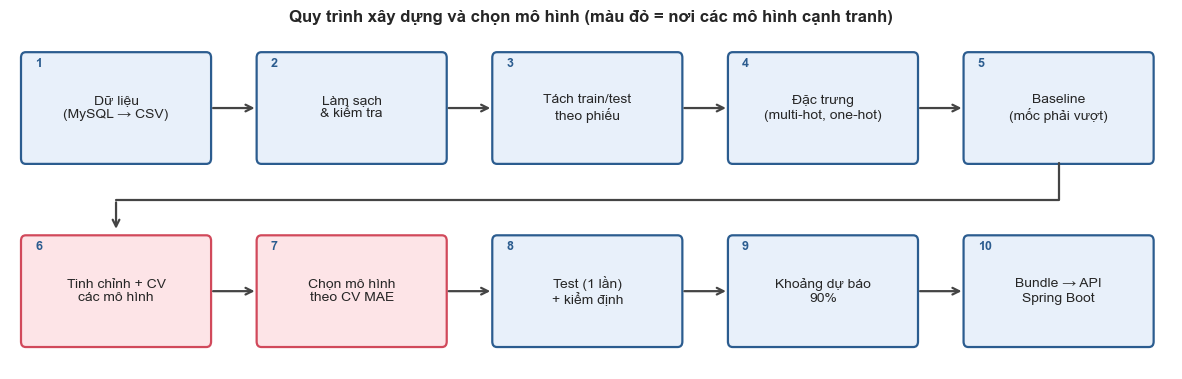

In [8]:
# Sơ đồ tổng quan quy trình (mỗi ô là một bước của notebook)
from matplotlib.patches import FancyBboxPatch

steps = ["Dữ liệu\n(MySQL → CSV)", "Làm sạch\n& kiểm tra", "Tách train/test\ntheo phiếu", "Đặc trưng\n(multi-hot, one-hot)",
         "Baseline\n(mốc phải vượt)", "Tinh chỉnh + CV\ncác mô hình", "Chọn mô hình\ntheo CV MAE", "Test (1 lần)\n+ kiểm định",
         "Khoảng dự báo\n90%", "Bundle → API\nSpring Boot"]
fig, ax = plt.subplots(figsize=(15, 4.4)); ax.axis("off")
per_row = 5
pos = []
for i, t in enumerate(steps):
    r, c = divmod(i, per_row)
    x, y = c * 3.0, 1.9 - r * 2.0
    pos.append((x, y))
    ax.add_patch(FancyBboxPatch((x, y), 2.3, 1.1, boxstyle="round,pad=0.06", fc="#e8f0fa" if i not in (5, 6) else "#fde4e7",
                                ec=NEUTRAL if i not in (5, 6) else BEST_COLOR, lw=1.6))
    ax.text(x + 1.15, y + 0.55, t, ha="center", va="center", fontsize=10)
    ax.text(x + 0.12, y + 1.0, str(i + 1), fontsize=9, fontweight="bold", color=NEUTRAL)
for i in range(len(steps) - 1):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if y1 == y2:
        ax.annotate("", xy=(x2 - 0.05, y2 + 0.55), xytext=(x1 + 2.35, y1 + 0.55), arrowprops=dict(arrowstyle="->", lw=1.6, color="#444"))
    else:   # chuyển hàng: đi xuống khoảng trống giữa hai hàng, sang trái, rồi xuống ô kế tiếp (không cắt ngang chữ)
        ym = (y1 + y2 + 1.1) / 2
        ax.plot([x1 + 1.15, x1 + 1.15, x2 + 1.15], [y1 - 0.05, ym, ym], color="#444", lw=1.6)
        ax.annotate("", xy=(x2 + 1.15, y2 + 1.2), xytext=(x2 + 1.15, ym), arrowprops=dict(arrowstyle="->", lw=1.6, color="#444"))
ax.set_xlim(-0.2, 14.6); ax.set_ylim(-0.4, 3.3)
ax.set_title("Quy trình xây dựng và chọn mô hình (màu đỏ = nơi các mô hình cạnh tranh)")
savefig("00_pipeline_overview"); plt.show()

## Bước 2. Nạp dữ liệu

**Nhiệm vụ:** đọc dữ liệu thô xuất từ MySQL bởi `scripts/01_extract_raw_data.py` (mỗi phiếu hoàn tất = một dòng) và kiểm tra hình dạng, kiểu dữ liệu, giá trị thiếu.

$$D_{\text{raw}} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{N}, \qquad y_i \in \mathbb{R}^{+}\ \text{(phút)}$$

**Lưu ý trung thực:** dữ liệu hiện tại do script seed sinh theo quy luật nghiệp vụ, tức là **dữ liệu mô phỏng**. Mô hình học lại quy luật đó. Vì vậy mọi con số trong notebook đo *độ khớp với quy luật mô phỏng*, chưa phải hiệu năng vận hành thật. Cờ `SYNTHETIC_DATA` trong config đưa sự thật này vào metadata của model và API.

In [9]:
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Chưa có {RAW_DATA_PATH}. Chạy scripts/01_extract_raw_data.py trước.")

df_raw = pd.read_csv(RAW_DATA_PATH)
print(f"Dữ liệu thô: {df_raw.shape[0]} dòng x {df_raw.shape[1]} cột | SYNTHETIC_DATA = {SYNTHETIC_DATA}")
display(df_raw.head(3))
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "thiếu": df_raw.isna().sum(), "giá trị khác nhau": df_raw.nunique()}))

Dữ liệu thô: 832 dòng x 22 cột | SYNTHETIC_DATA = True


,ticket_id,ticket_code,branch_id,device_model_id,device_model_name,total_services_count,service_issue_ids_list,service_issue_names_list,service_type_codes_list,total_catalog_standard_duration_minutes,...,technician_name,is_reassigned,count_waiting_part_events,count_waiting_approval_events,total_pause_events_count,total_pause_duration_minutes,actual_repair_started_at,actual_repair_completed_at,actual_repair_duration_minutes,net_repair_duration_minutes
0,11204,ST-202610-00847,1070,1445,iPad Pro M3,2,"1,6",Pin + Loa ngoài,"REPAIR, REPLACEMENT",105.0,...,Nguyễn Minh Hoàng,0,0.0,1.0,1,20.0,2026-10-11 10:26:09.000000,2026-10-11 11:56:09.000000,90,70.0
1,11203,ST-202610-00846,1070,1444,iPad Pro M2,1,2,Camera sau,REPAIR,45.0,...,Trần Quốc Huy,0,1.0,0.0,1,30.0,2026-10-11 10:26:09.000000,2026-10-11 11:41:09.000000,75,45.0
2,11202,ST-202610-00845,1070,1444,iPad Pro M2,1,3,Camera trước,REPAIR,45.0,...,Nguyễn Minh Hoàng,0,1.0,1.0,2,54.0,2026-10-18 10:26:09.000000,2026-10-18 12:07:09.000000,101,47.0


,dtype,thiếu,giá trị khác nhau
ticket_id,int64,0,832
ticket_code,object,0,832
branch_id,int64,0,1
device_model_id,int64,0,21
device_model_name,object,0,21
total_services_count,int64,0,2
service_issue_ids_list,object,0,11
service_issue_names_list,object,0,11
service_type_codes_list,object,0,3
total_catalog_standard_duration_minutes,float64,0,9


## Bước 3. Làm sạch dữ liệu

**Nhiệm vụ:** chỉ giữ các dòng mà nhãn $y$ có nghĩa và độc lập.

| Quy tắc | Lý do |
|---|---|
| Loại phiếu **chuyển giao KTV** (`is_reassigned = 1`) | Thời gian bị trộn của nhiều người, nhãn không còn thuộc một KTV |
| Loại `y ≤ 0` hoặc `total_services_count = 0` | Nhãn vô nghĩa, không có hạng mục để dự đoán |
| **Mỗi phiếu đúng một dòng** (`drop_duplicates(ticket_id)`) | Một phiếu xuất hiện hai lần ở train và test là rò rỉ, lại có thể mang hai nhãn mâu thuẫn |

Biểu đồ dưới đây cho thấy mỗi quy tắc loại bao nhiêu dòng, để báo cáo minh bạch.

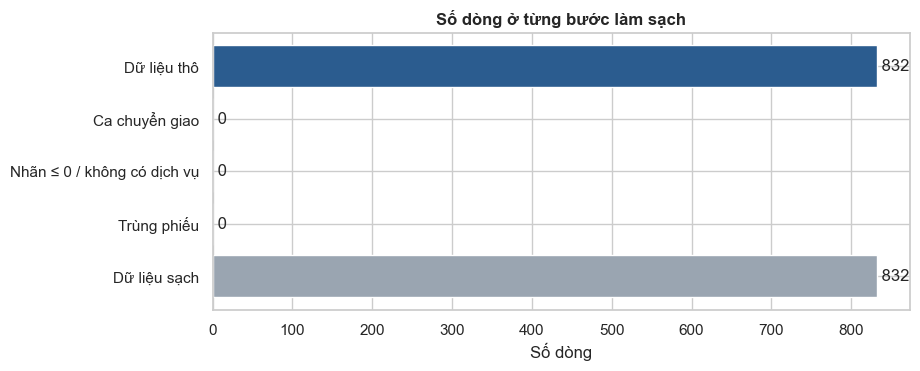

Dữ liệu sạch: 832 phiếu | 3 KTV | 21 thiết bị | 11 tổ hợp mã lỗi


In [10]:
df, clean_report = clean_training_data(df_raw, TARGET_COL, GROUP_COL)

labels = ["Dữ liệu thô", "Ca chuyển giao", "Nhãn ≤ 0 / không có dịch vụ", "Trùng phiếu", "Dữ liệu sạch"]
vals = [clean_report["rows_raw"], clean_report.get("dropped_reassigned", 0),
        clean_report["dropped_invalid_target_or_no_service"], clean_report["dropped_duplicate_tickets"], clean_report["rows_clean"]]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(labels[::-1], vals[::-1], color=[NEUTRAL, "#e07a5f", "#e07a5f", "#e07a5f", BASE_COLOR][::-1])
for i, v in enumerate(vals[::-1]):
    ax.text(v, i, f" {v}", va="center")
ax.set_title("Số dòng ở từng bước làm sạch"); ax.set_xlabel("Số dòng"); savefig("03_cleaning"); plt.show()

# Kiểm tra hậu điều kiện: nếu sai thì dừng ngay, không đi tiếp trên dữ liệu bẩn
assert df[GROUP_COL].is_unique, "Còn phiếu trùng"
assert (df.get("is_reassigned", pd.Series(0, index=df.index)) == 0).all(), "Còn ca chuyển giao"
assert (df[TARGET_COL] > 0).all() and (df["total_services_count"] > 0).all()
print(f"Dữ liệu sạch: {len(df)} phiếu | {df['technician_id'].nunique()} KTV | {df['device_model_id'].nunique()} thiết bị | "
      f"{df[ISSUE_COL].map(issue_key).nunique()} tổ hợp mã lỗi")

## Bước 4. Phân tích khám phá dữ liệu (EDA)

**Nhiệm vụ:** hiểu cấu trúc dữ liệu *trước khi* chọn mô hình. Mỗi biểu đồ trả lời một câu hỏi và ảnh hưởng trực tiếp tới lựa chọn thiết kế phía sau.

### 4.1. Phân phối của nhãn $y$

Xem hình dạng phân phối, độ lệch (skewness) và ngoại lai. Độ lệch mẫu:

$$g_1 = \frac{\frac{1}{N}\sum_i (y_i - \bar{y})^3}{\left(\frac{1}{N}\sum_i (y_i - \bar{y})^2\right)^{3/2}}$$

$g_1 > 0$ nghĩa là đuôi phải dài (một số ca sửa rất lâu).

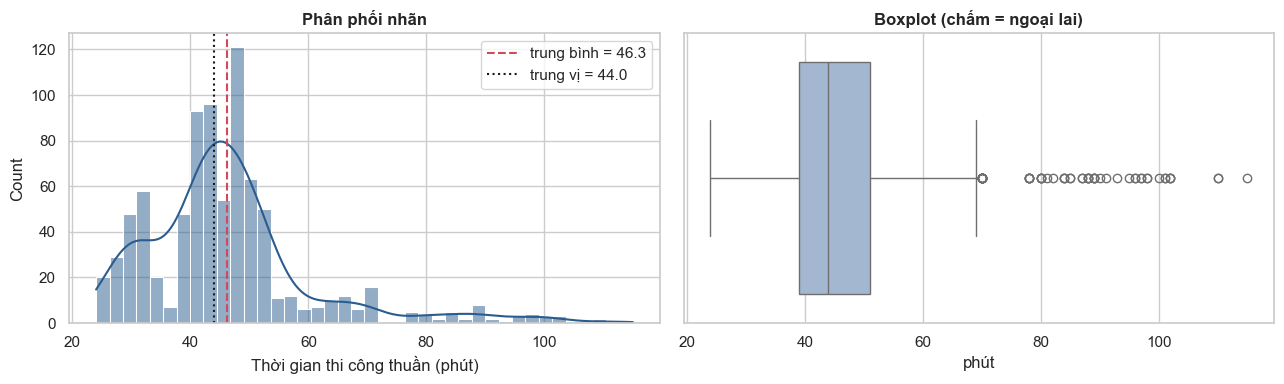

,count,mean,std,min,5%,25%,50%,75%,95%,max
y (phút),832.0,46.28,14.46,24.0,28.0,39.0,44.0,51.0,78.0,115.0


Độ lệch g1 = 1.619


In [11]:
y_all = df[TARGET_COL]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y_all, bins=40, kde=True, ax=ax[0], color=NEUTRAL)
ax[0].axvline(y_all.mean(), ls="--", c=BEST_COLOR, label=f"trung bình = {y_all.mean():.1f}")
ax[0].axvline(y_all.median(), ls=":", c="k", label=f"trung vị = {y_all.median():.1f}")
ax[0].set(xlabel="Thời gian thi công thuần (phút)", title="Phân phối nhãn"); ax[0].legend()
sns.boxplot(x=y_all, ax=ax[1], color="#9bb8d8"); ax[1].set(xlabel="phút", title="Boxplot (chấm = ngoại lai)")
plt.tight_layout(); savefig("04_1_target_distribution"); plt.show()
display(y_all.describe(percentiles=[.05, .25, .5, .75, .95]).round(2).to_frame("y (phút)").T)
print(f"Độ lệch g1 = {stats.skew(y_all):.3f}")

### 4.2. Định mức catalog và thời gian thực tế

Catalog là "câu trả lời có sẵn" của hệ thống. Nếu catalog đã dự đoán tốt thì ML không có nhiều việc để làm; nếu lệch có hệ thống thì đó là chỗ ML tạo giá trị. Hệ số tương quan Pearson:

$$r = \frac{\sum_i (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_i (x_i-\bar{x})^2}\ \sqrt{\sum_i (y_i-\bar{y})^2}}$$

Đường nét đứt $y=x$ là "thực tế đúng bằng định mức".

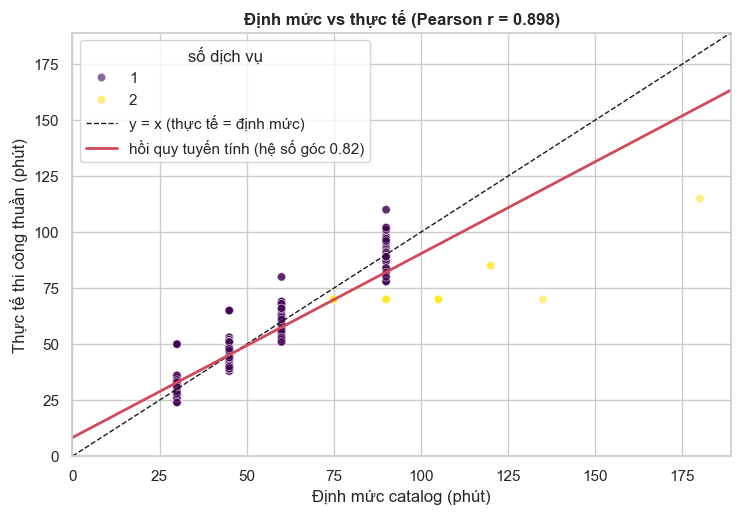

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.scatterplot(data=df, x=CATALOG_COL, y=TARGET_COL, hue="total_services_count", palette="viridis", alpha=0.6, ax=ax)
lim = [0, max(df[CATALOG_COL].max(), df[TARGET_COL].max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="y = x (thực tế = định mức)")
slope, intercept = np.polyfit(df[CATALOG_COL], df[TARGET_COL], 1)
xs = np.array(lim); ax.plot(xs, slope * xs + intercept, color=BEST_COLOR, lw=2, label=f"hồi quy tuyến tính (hệ số góc {slope:.2f})")
r = np.corrcoef(df[CATALOG_COL], df[TARGET_COL])[0, 1]
ax.set(xlim=lim, ylim=lim, xlabel="Định mức catalog (phút)", ylabel="Thực tế thi công thuần (phút)",
       title=f"Định mức vs thực tế (Pearson r = {r:.3f})"); ax.legend(title="số dịch vụ")
savefig("04_2_catalog_vs_actual"); plt.show()

### 4.3. Hiệu ứng gộp nhiều dịch vụ và tín hiệu KTV

Đặt tỉ lệ $\rho_i = y_i / \text{catalog}_i$ (thực tế / định mức).

* **Gộp dịch vụ:** làm nhiều dịch vụ trong một lần tháo máy thường tiết kiệm thời gian, nên $\rho$ giảm khi số dịch vụ tăng. Đây là quan hệ **phi tuyến**, lý do để dùng mô hình cây.
* **Tín hiệu KTV:** nếu các KTV thật sự khác nhau về tốc độ thì $\rho$ phải khác nhau giữa các KTV. Kiểm định bằng **ANOVA một yếu tố** trên các ca một dịch vụ (để loại hiệu ứng gộp):

$$F = \frac{MS_B}{MS_W} = \frac{SS_B/(k-1)}{SS_W/(N-k)}, \qquad \eta^2 = \frac{SS_B}{SS_T}$$

$F$ lớn / $p<0.05$ nghĩa là có khác biệt. $\eta^2$ cho biết *độ lớn* hiệu ứng (≈0.01 nhỏ, 0.06 vừa, 0.14 lớn). **Nếu không có tín hiệu KTV trong dữ liệu thì không mô hình nào học được sự khác biệt giữa các KTV**, và việc "dự đoán theo KTV" chưa có cơ sở.

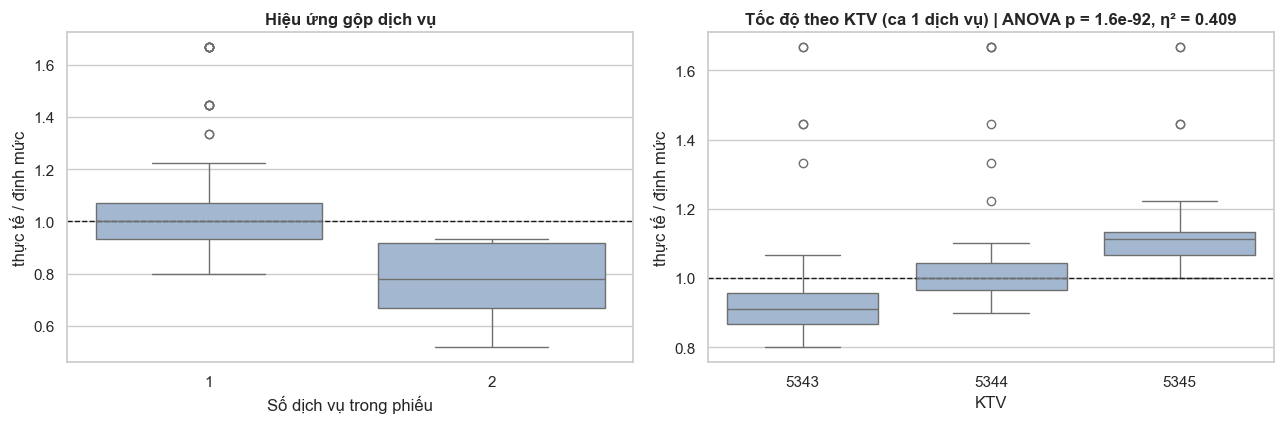

,count,mean,std
technician_id,,,
5343,269,0.927,0.100
5344,264,1.011,0.094
5345,274,1.110,0.077


ANOVA: F = 278.152, p = 1.55e-92, η² = 0.409 (hiệu ứng lớn)
=> CÓ khác biệt KTV có ý nghĩa thống kê.


In [13]:
df["ratio"] = df[TARGET_COL] / df[CATALOG_COL]
single = df[df["total_services_count"] == 1].copy()

groups = [g.to_numpy() for _, g in single.groupby("technician_id")["ratio"] if len(g) > 1]
F, p_anova = stats.f_oneway(*groups)
grand = single["ratio"].mean()
ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups); sst = ((single["ratio"] - grand) ** 2).sum()
eta2 = ssb / sst
effect = "nhỏ" if eta2 < 0.06 else ("vừa" if eta2 < 0.14 else "lớn")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
sns.boxplot(data=df, x="total_services_count", y="ratio", ax=ax[0], color="#9bb8d8")
ax[0].axhline(1, ls="--", c="k", lw=1); ax[0].set(xlabel="Số dịch vụ trong phiếu", ylabel="thực tế / định mức", title="Hiệu ứng gộp dịch vụ")
sns.boxplot(data=single, x="technician_id", y="ratio", ax=ax[1], color="#9bb8d8")
ax[1].axhline(1, ls="--", c="k", lw=1)
ax[1].set(xlabel="KTV", ylabel="thực tế / định mức", title=f"Tốc độ theo KTV (ca 1 dịch vụ) | ANOVA p = {p_anova:.2g}, η² = {eta2:.3f}")
plt.tight_layout(); savefig("04_3_bundling_and_technician"); plt.show()

display(single.groupby("technician_id")["ratio"].agg(["count", "mean", "std"]).round(3))
ktv_signal = bool(p_anova < 0.05)
print(f"ANOVA: F = {F:.3f}, p = {p_anova:.3g}, η² = {eta2:.3f} (hiệu ứng {effect})")
print("=> " + ("CÓ khác biệt KTV có ý nghĩa thống kê." if ktv_signal else
               "KHÔNG có bằng chứng KTV khác nhau: dự đoán theo KTV chưa có cơ sở, cần sửa script sinh dữ liệu."))

### 4.4. Tốc độ theo (loại lỗi × KTV)

Nếu KTV khác nhau *tùy loại sửa chữa* (người giỏi pin, người giỏi màn hình), bảng nhiệt dưới đây sẽ có các ô đậm nhạt khác nhau theo cột. Đây là loại **tương tác** mà mô hình cây học được còn hồi quy tuyến tính thì không.

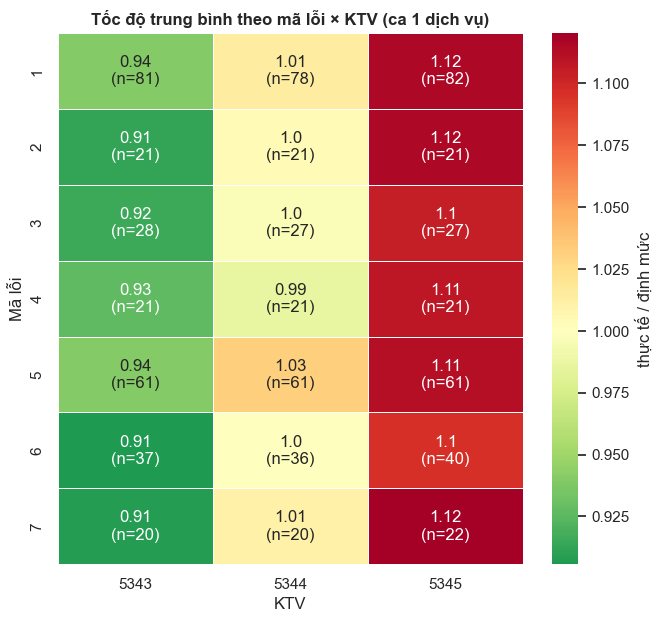

In [14]:
pivot = (single.assign(issue=single[ISSUE_COL].map(issue_key))
               .pivot_table(index="issue", columns="technician_id", values="ratio", aggfunc="mean"))
counts = (single.assign(issue=single[ISSUE_COL].map(issue_key))
                .pivot_table(index="issue", columns="technician_id", values="ratio", aggfunc="count"))
annot = pivot.round(2).astype(str) + "\n(n=" + counts.fillna(0).astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(7.5, 0.7 * len(pivot) + 2))
sns.heatmap(pivot, annot=annot, fmt="", cmap="RdYlGn_r", center=1.0, linewidths=0.5, ax=ax, cbar_kws={"label": "thực tế / định mức"})
ax.set(xlabel="KTV", ylabel="Mã lỗi", title="Tốc độ trung bình theo mã lỗi × KTV (ca 1 dịch vụ)")
savefig("04_4_issue_by_technician"); plt.show()

### 4.5. Ma trận tương quan

Tương quan Pearson giữa nhãn và các đặc trưng số/mã lỗi. **Chỉ để tham khảo, không dùng để loại đặc trưng:** Pearson chỉ đo quan hệ *tuyến tính*, trong khi mô hình cây bắt được quan hệ phi tuyến và tương tác. Một cột có $|r|$ nhỏ vẫn có thể rất hữu ích khi kết hợp với cột khác.

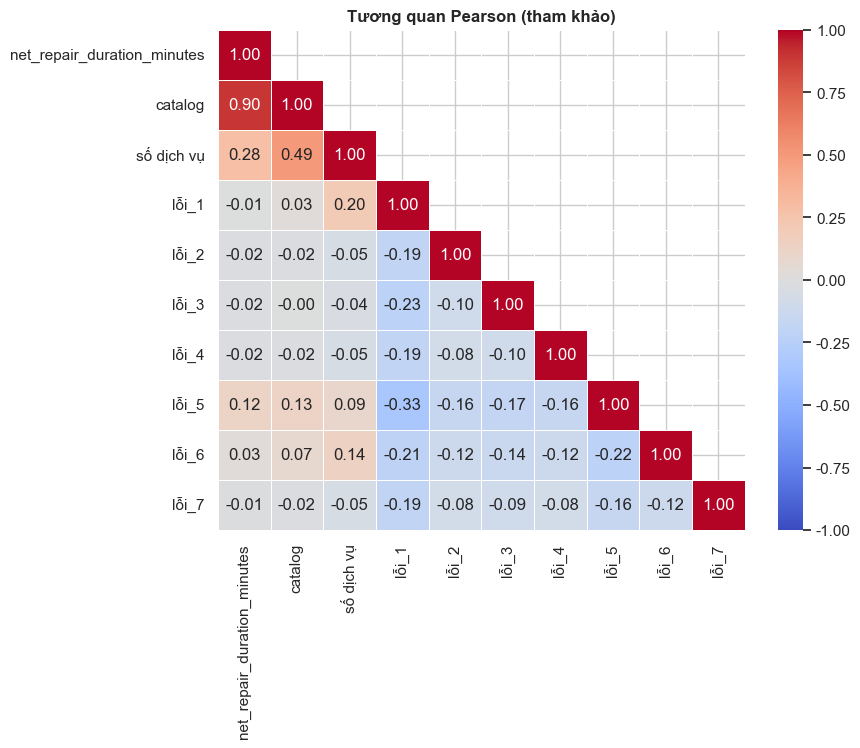

In [15]:
eda = pd.DataFrame({TARGET_COL: df[TARGET_COL], "catalog": df[CATALOG_COL], "số dịch vụ": df["total_services_count"]})
for k in sorted({i for v in df[ISSUE_COL] for i in parse_issue_ids(v)}):
    eda[f"lỗi_{k}"] = [int(k in parse_issue_ids(v)) for v in df[ISSUE_COL]]
corr = eda.corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax)
ax.set_title("Tương quan Pearson (tham khảo)"); savefig("04_5_correlation"); plt.show()

## Bước 5. Thời điểm dự báo $t_0$ và chống rò rỉ dữ liệu

**Nhiệm vụ:** chỉ cho mô hình thấy những gì **hệ thống biết ở thời điểm cần dự đoán**. Đặc trưng nào chỉ biết *sau khi sửa xong* thì khi triển khai không tồn tại; dùng nó để train là mô hình "gian lận", điểm số cao nhưng vô dụng.

$$\mathbf{x}_i \subseteq \mathcal{I}(t_0)\quad(\text{thông tin có tại } t_0),\qquad y_i \notin \mathcal{I}(t_0)$$

Hai cột bị loại có chủ đích dù không phải thông tin tương lai:

* `branch_id`: hiện chỉ có một chi nhánh, là hằng số nên không mang thông tin.
* `total_parts_quantity_used`: lúc train là số linh kiện **đã xuất kho thực tế**, lúc dự đoán chưa biết nên phải đoán bằng công thức khác, gây **lệch phân phối giữa train và serve**.

In [16]:
FEATURE_COLS = NUM_COLS + CAT_COLS + [ISSUE_COL]
policy = pd.DataFrame([
    ("device_model_id", "Biết khi tiếp nhận", "DÙNG"), ("technician_id", "Biết khi phân công (hoặc thử từng ứng viên)", "DÙNG"),
    (ISSUE_COL, "Biết khi lập hạng mục sửa chữa", "DÙNG"), ("total_services_count", "Biết khi lập hạng mục", "DÙNG"),
    (CATALOG_COL, "Tra từ catalog khi lập hạng mục", "DÙNG"),
    ("branch_id", "Hằng số (1 chi nhánh)", "BỎ: không mang thông tin"),
    ("total_parts_quantity_used", "Chỉ biết sau khi xuất kho", "BỎ: lệch train/serve"),
    ("actual_repair_started_at / completed_at / duration", "Chỉ biết sau khi sửa", "BỎ: rò rỉ tương lai"),
    ("total_pause_duration / events, count_waiting_*", "Chỉ biết sau khi sửa", "BỎ: rò rỉ tương lai"),
    ("is_reassigned", "Chỉ biết sau khi sửa", "BỎ: đã lọc ở bước làm sạch"),
    ("ticket_id, ticket_code, *_name, *_names_list", "Định danh / văn bản thô", "BỎ: không phải đặc trưng"),
], columns=["Cột", "Thời điểm biết", "Quyết định"])
display(policy)

FORBIDDEN = ["actual_repair_started_at", "actual_repair_completed_at", "actual_repair_duration_minutes", "total_pause_duration_minutes",
             "total_pause_events_count", "count_waiting_part_events", "count_waiting_approval_events", "is_reassigned",
             "total_parts_quantity_used", TARGET_COL]
assert not set(FEATURE_COLS) & set(FORBIDDEN), "Đặc trưng đang chứa cột bị cấm!"
print("Đặc trưng đầu vào:", FEATURE_COLS)
print("branch_id có", df["branch_id"].nunique(), "giá trị duy nhất -> hằng số" if df["branch_id"].nunique() == 1 else "giá trị")

,Cột,Thời điểm biết,Quyết định
0,device_model_id,Biết khi tiếp nhận,DÙNG
1,technician_id,Biết khi phân công (hoặc thử từng ứng viên),DÙNG
2,service_issue_ids_list,Biết khi lập hạng mục sửa chữa,DÙNG
3,total_services_count,Biết khi lập hạng mục,DÙNG
4,total_catalog_standard_duration_minutes,Tra từ catalog khi lập hạng mục,DÙNG
5,branch_id,Hằng số (1 chi nhánh),BỎ: không mang thông tin
6,total_parts_quantity_used,Chỉ biết sau khi xuất kho,BỎ: lệch train/serve
7,actual_repair_started_at / completed_at / dura...,Chỉ biết sau khi sửa,BỎ: rò rỉ tương lai
8,"total_pause_duration / events, count_waiting_*",Chỉ biết sau khi sửa,BỎ: rò rỉ tương lai
9,is_reassigned,Chỉ biết sau khi sửa,BỎ: đã lọc ở bước làm sạch


Đặc trưng đầu vào: ['total_services_count', 'total_catalog_standard_duration_minutes', 'device_model_id', 'technician_id', 'service_issue_ids_list']
branch_id có 1 giá trị duy nhất -> hằng số


## Bước 6. Tách train/test **theo phiếu**

**Nhiệm vụ:** tạo một tập test độc lập thật sự. Tập test đóng vai "phiếu tương lai" mà mô hình chưa từng thấy, và **chỉ được dùng một lần ở cuối**.

$$D = D_{\text{train}} \cup D_{\text{test}}, \qquad \text{tickets}(D_{\text{train}}) \cap \text{tickets}(D_{\text{test}}) = \emptyset$$

Tách **theo nhóm (phiếu)** thay vì theo dòng để không bao giờ có một phiếu nằm ở cả hai tập. Mọi bước học (mã hóa, tinh chỉnh, chọn mô hình) chỉ được dùng $D_{\text{train}}$.

Chế độ tách: group | train = 665 phiếu | test = 167 phiếu | không phiếu nào ở cả hai tập


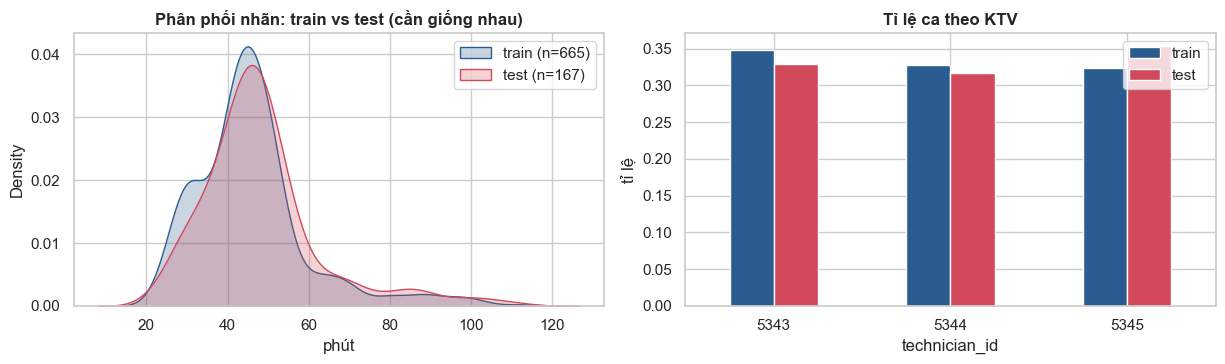

In [17]:
def split_train_test(frame):
    if SPLIT_MODE == "time" and TIME_COL in frame.columns:
        d = frame.assign(_t=pd.to_datetime(frame[TIME_COL], errors="coerce")).sort_values(["_t", GROUP_COL])
        cut = int(len(d) * (1 - TEST_SIZE))
        return d.iloc[:cut].drop(columns="_t").reset_index(drop=True), d.iloc[cut:].drop(columns="_t").reset_index(drop=True)
    tr, te = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=SEED).split(frame, groups=frame[GROUP_COL]))
    return frame.iloc[tr].reset_index(drop=True), frame.iloc[te].reset_index(drop=True)

df_model = df.drop(columns=["ratio"], errors="ignore")   # bỏ cột phụ chỉ dùng cho EDA
train, test = split_train_test(df_model)
assert set(train[GROUP_COL]).isdisjoint(set(test[GROUP_COL])), "Rò rỉ: có phiếu ở cả train và test"
y_tr, y_te = train[TARGET_COL].to_numpy(float), test[TARGET_COL].to_numpy(float)
print(f"Chế độ tách: {SPLIT_MODE} | train = {len(train)} phiếu | test = {len(test)} phiếu | không phiếu nào ở cả hai tập")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))
sns.kdeplot(y_tr, fill=True, label=f"train (n={len(train)})", ax=ax[0], color=NEUTRAL)
sns.kdeplot(y_te, fill=True, label=f"test (n={len(test)})", ax=ax[0], color=BEST_COLOR)
ax[0].set(xlabel="phút", title="Phân phối nhãn: train vs test (cần giống nhau)"); ax[0].legend()
for col, c in (("technician_id", NEUTRAL),):
    t = pd.concat([train[col].value_counts(normalize=True).rename("train"), test[col].value_counts(normalize=True).rename("test")], axis=1).fillna(0)
    t.plot.bar(ax=ax[1], color=[NEUTRAL, BEST_COLOR]); ax[1].set(title="Tỉ lệ ca theo KTV", ylabel="tỉ lệ"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); savefig("06_train_test_split"); plt.show()

## Bước 7. Xây dựng đặc trưng

**Nhiệm vụ:** biến bảng thô thành ma trận số $\mathbf{X} \in \mathbb{R}^{N \times d}$. Bộ mã hóa `RepairFeatureBuilder` **chỉ `fit` trên train**; với phiếu lạ nó đưa ra toàn 0 (hoặc nhóm `unknown`) thay vì báo lỗi.

1. **Tỉ lệ nghiệp vụ** (cây khó tự tạo phép chia):
$$x_{\text{dur/svc}} = \frac{\text{catalog}}{\text{số dịch vụ}}$$

2. **Mã hóa đa nhãn (multi-hot)** cho tập mã lỗi $\mathcal{S}_i$ (một phiếu có thể có nhiều lỗi):
$$v_{i,k} = \mathbb{1}[\,k \in \mathcal{S}_i\,], \quad k = 1,\dots,K$$

3. **One-hot** cho ID thiết bị và ID KTV. ID là *nhãn danh định*, không phải con số có thứ tự (KTV 5345 không "lớn hơn" KTV 5343):
$$u_{i,c} = \mathbb{1}[\,\text{id}_i = c\,]$$

Hai chế độ mã hóa để so sánh công bằng:

| Chế độ | Dùng cho | Cách xử lý ID |
|---|---|---|
| `ohe` | Ridge, Cây, RF, XGBoost, LightGBM, CatBoost | cột 0/1 |
| `native` | CatBoost (native) | giữ chuỗi, CatBoost dùng *ordered target statistics* |

Ma trận đặc trưng 'ohe'   : train (665, 34) | test (167, 34)
Ma trận đặc trưng 'native': train (665, 12) | test (167, 12)
Từ vựng học từ train: 7 mã lỗi [1, 2, 3, 4, 5, 6, 7] | 21 thiết bị | KTV [5343, 5344, 5345]


,total_services_count,total_catalog_standard_duration_minutes,duration_per_service,issue_1,issue_2,issue_3,issue_4,issue_5,issue_6,issue_7,...,device_model_id__1429,device_model_id__1440,device_model_id__1441,device_model_id__1442,device_model_id__1443,device_model_id__1444,device_model_id__1445,technician_id__5343,technician_id__5344,technician_id__5345
0,2.0,105.0,52.5,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,1.0,45.0,45.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,1.0,45.0,45.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


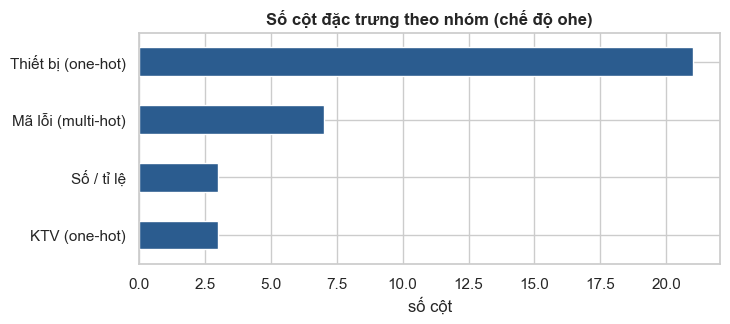

Giá trị lạ phát hiện được: {'device_model_id': [888888], 'technician_id': [999999]} | biến đổi vẫn chạy: (2, 34)


In [18]:
builders = {
    "ohe": RepairFeatureBuilder(NUM_COLS, CAT_COLS, ISSUE_COL, cat_mode="ohe").fit(train),
    "native": RepairFeatureBuilder(NUM_COLS, CAT_COLS, ISSUE_COL, cat_mode="native").fit(train),
}
X_tr_mode = {m: b.transform(train) for m, b in builders.items()}
X_te_mode = {m: b.transform(test) for m, b in builders.items()}

b = builders["ohe"]
print(f"Ma trận đặc trưng 'ohe'   : train {X_tr_mode['ohe'].shape} | test {X_te_mode['ohe'].shape}")
print(f"Ma trận đặc trưng 'native': train {X_tr_mode['native'].shape} | test {X_te_mode['native'].shape}")
print(f"Từ vựng học từ train: {len(b.issue_vocab_)} mã lỗi {b.issue_vocab_} | {len(b.categories_['device_model_id'])} thiết bị | KTV {b.categories_['technician_id']}")
display(X_tr_mode["ohe"].head(3))

grp = pd.Series([("Mã lỗi (multi-hot)" if c.startswith("issue_") else "Thiết bị (one-hot)" if c.startswith("device_model_id__")
                  else "KTV (one-hot)" if c.startswith("technician_id__") else "Số / tỉ lệ") for c in b.feature_names_]).value_counts()
fig, ax = plt.subplots(figsize=(7.5, 3)); grp.sort_values().plot.barh(ax=ax, color=NEUTRAL)
ax.set(title="Số cột đặc trưng theo nhóm (chế độ ohe)", xlabel="số cột"); savefig("07_feature_groups"); plt.show()

# Kiểm tra chống rò rỉ: phiếu có KTV/thiết bị lạ không làm hỏng bộ mã hóa
probe = test.head(2).assign(technician_id=[5343, 999999], device_model_id=[test["device_model_id"].iloc[0], 888888])
print("Giá trị lạ phát hiện được:", b.unknown_values(probe), "| biến đổi vẫn chạy:", b.transform(probe).shape)

## Bước 8. Thước đo đánh giá

**Nhiệm vụ:** định nghĩa *thế nào là tốt*. Với $e_i = \hat{y}_i - y_i$ (đơn vị phút):

$$\text{MAE} = \frac{1}{N}\sum_i |e_i| \quad\text{(KPI chính: "trung bình lệch bao nhiêu phút")}$$

$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_i e_i^2} \quad\text{(phạt nặng ca lệch lớn)}$$

$$R^2 = 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2} \quad\text{(tỉ lệ biến thiên được giải thích)}$$

Thêm các chỉ số gắn với nghiệp vụ:

* $\text{P90}=\text{Quantile}_{0.9}(|e_i|)$: 90% ca sai không quá bao nhiêu phút.
* $\text{within-}\delta = \frac{1}{N}\sum_i \mathbb{1}[|e_i|\le\delta]$ với $\delta=5$ phút: tỉ lệ ca đoán chuẩn trong 5 phút.
* $\text{bias} = \frac{1}{N}\sum_i e_i$: dương nghĩa là đoán dôi, âm nghĩa là đoán hụt (ảnh hưởng ETA khách thấy).

**Khoảng tin cậy cho MAE (bootstrap percentile):** lấy mẫu có hoàn lại $B=2000$ lần các $|e_i|$, tính trung bình mỗi lần, rồi lấy phân vị 2.5% và 97.5%. Với tập test chỉ vài trăm mẫu, MAE có sai số lấy mẫu đáng kể, nên hai mô hình hơn kém nhau trong khoảng này **chưa chắc hơn nhau thật**.

In [19]:
# Kiểm tra hàm đo bằng công thức tay (chắc rằng mọi con số về sau là chuẩn xác)
_y = np.array([30., 40., 50., 60.]); _p = np.array([33., 38., 50., 66.]); _e = _p - _y
rep = regression_report(_y, _p)
assert np.isclose(rep["MAE"], np.mean(np.abs(_e))) and np.isclose(rep["RMSE"], np.sqrt(np.mean(_e ** 2)))
assert np.isclose(rep["R2"], 1 - np.sum(_e ** 2) / np.sum((_y - _y.mean()) ** 2)) and np.isclose(rep["bias"], _e.mean())
print("Hàm đo khớp công thức:", {k: round(v, 3) for k, v in rep.items()})

Hàm đo khớp công thức: {'MAE': 2.75, 'RMSE': 3.5, 'R2': 0.902, 'P90_abs_err': 5.1, 'within_5min_pct': 75.0, 'bias': 1.75}


## Bước 9. Giao thức kiểm thử chéo (cross-validation)

**Nhiệm vụ:** ước lượng hiệu năng *để chọn mô hình* mà không đụng vào tập test. Dùng **$K$-fold theo nhóm** (`GroupKFold`): chia $D_{\text{train}}$ thành $K=5$ phần theo phiếu; lần lượt học trên 4 phần, kiểm tra trên 1 phần.

$$\text{CV-MAE} = \frac{1}{K}\sum_{k=1}^{K}\text{MAE}_k, \qquad s = \sqrt{\frac{1}{K-1}\sum_k(\text{MAE}_k-\text{CV-MAE})^2}, \qquad \text{SE} = \frac{s}{\sqrt{K}}$$

Mọi mô hình và baseline dùng **đúng cùng các fold**, nên so sánh là *so cùng một đề thi* (paired). SE cho biết độ bất định của CV-MAE: hai mô hình cách nhau ít hơn một SE là **hòa thống kê**.

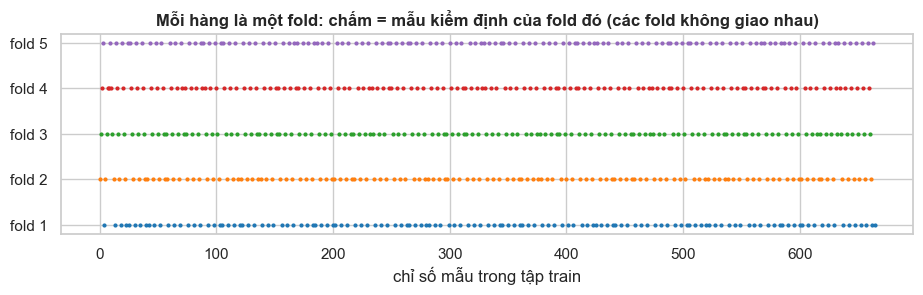

5 fold theo phiếu, kích thước kiểm định: [133, 133, 133, 133, 133]


In [20]:
gkf = GroupKFold(n_splits=CV_FOLDS)
folds = list(gkf.split(train, groups=train[GROUP_COL]))
for k, (a, v) in enumerate(folds):
    assert set(train.iloc[a][GROUP_COL]).isdisjoint(set(train.iloc[v][GROUP_COL]))

fig, ax = plt.subplots(figsize=(11, 2.6))
for k, (a, v) in enumerate(folds):
    ax.scatter(v, np.full(len(v), k), s=4, color=plt.cm.tab10(k))
ax.set(yticks=range(CV_FOLDS), yticklabels=[f"fold {k+1}" for k in range(CV_FOLDS)], xlabel="chỉ số mẫu trong tập train",
       title="Mỗi hàng là một fold: chấm = mẫu kiểm định của fold đó (các fold không giao nhau)")
savefig("09_cv_folds"); plt.show()
print(f"{CV_FOLDS} fold theo phiếu, kích thước kiểm định: {[len(v) for _, v in folds]}")

## Bước 10. Baseline: những "mốc" mô hình phải vượt

**Nhiệm vụ:** một mô hình học máy chỉ đáng dùng nếu **thắng được cách làm đơn giản**. Nếu không, ML chỉ thêm độ phức tạp.

| Baseline | Dự đoán | Ý nghĩa |
|---|---|---|
| B0 Trung bình | $\hat{y} = \bar{y}_{\text{train}}$ | Không dùng thông tin gì |
| B1 Định mức catalog | $\hat{y} = \text{catalog}$ | Hệ thống hiện tại đang làm gì |
| B2 Tuyến tính theo catalog | $\hat{y} = a\cdot\text{catalog}+b$ | Hiệu chỉnh tuyến tính định mức |
| B3 Bảng tra (lỗi × KTV) | trung bình $y$ của cùng tổ hợp mã lỗi và KTV | "Học thuộc" bảng, không tổng quát hóa |

**B3 là đối thủ đáng gờm nhất:** khi dữ liệu chỉ có ít tổ hợp, bảng tra gần như đạt trần chính xác. Nếu mô hình ML chỉ nhỉnh hơn B3 một chút thì phải nói thẳng: giá trị của ML là **tổng quát hóa** cho tổ hợp chưa gặp, không phải độ chính xác trên các tổ hợp đã quen.

Baseline cũng được đánh giá bằng **cùng các fold CV** để so sánh công bằng.

,cv_mae,cv_std,cv_rmse,cv_r2
name,,,,
B0 Trung bình,9.743,0.655,14.325,-0.001
B1 Định mức catalog,4.304,0.387,6.999,0.761
B2 Tuyến tính theo catalog,4.495,0.333,6.544,0.791
B3 Bảng tra (lỗi x KTV),8.382,0.706,13.567,0.102


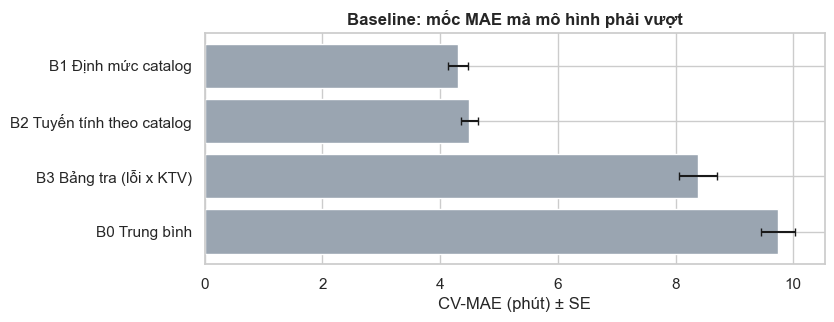

In [21]:
def collect(name, kind, oof_pred, fold_maes=None, **extra):
    # Gom kết quả CV chuẩn hóa cho cả baseline lẫn mô hình
    if fold_maes is None:
        fold_maes = np.array([np.mean(np.abs(oof_pred[v] - y_tr[v])) for _, v in folds])
    rep = regression_report(y_tr, oof_pred)
    return {"name": name, "kind": kind, "cv_mae": float(np.mean(fold_maes)), "cv_std": float(np.std(fold_maes, ddof=1)),
            "se": float(np.std(fold_maes, ddof=1) / np.sqrt(len(fold_maes))), "cv_rmse": rep["RMSE"], "cv_r2": rep["R2"],
            "fold_maes": np.asarray(fold_maes), **extra}

# Dự đoán out-of-fold của baseline: mỗi mẫu được dự đoán bởi baseline học từ các fold KHÔNG chứa nó
base_names = list(baseline_predictions(train.iloc[folds[0][0]], train.iloc[folds[0][1]], TARGET_COL, ISSUE_COL))
oof_base = {n: np.zeros(len(train)) for n in base_names}
for a, v in folds:
    for n, p in baseline_predictions(train.iloc[a], train.iloc[v], TARGET_COL, ISSUE_COL).items():
        oof_base[n][v] = p
cv_rows = [collect(n, "baseline", oof_base[n], train_time=0.0, best_params={}) for n in base_names]

display(pd.DataFrame(cv_rows)[["name", "cv_mae", "cv_std", "cv_rmse", "cv_r2"]].round(3).set_index("name"))
fig, ax = plt.subplots(figsize=(8, 3))
d = pd.DataFrame(cv_rows).sort_values("cv_mae", ascending=False)
ax.barh(d["name"], d["cv_mae"], xerr=d["se"], color=BASE_COLOR, capsize=3)
ax.set(xlabel="CV-MAE (phút) ± SE", title="Baseline: mốc MAE mà mô hình phải vượt"); savefig("10_baselines_cv"); plt.show()

## Bước 11. Các mô hình ứng viên

**Nhiệm vụ:** đưa các họ thuật toán khác nhau vào cùng một cuộc thi. Mỗi họ đại diện cho một giả định khác nhau về dữ liệu.

**Ridge (tuyến tính, có chuẩn hóa).** Giả định quan hệ tuyến tính, dùng làm "chứng cứ" cho việc cần mô hình phi tuyến:
$$\min_{\mathbf{w}}\ \sum_i (y_i - \mathbf{w}^\top\mathbf{x}_i)^2 + \alpha\lVert\mathbf{w}\rVert_2^2$$

**Cây quyết định.** Chia không gian đặc trưng thành các vùng; mỗi bước chọn đặc trưng $j$ và ngưỡng $s$ làm giảm tổng bình phương sai số nhiều nhất, dự đoán là trung bình của vùng:
$$\min_{j,s}\left[\sum_{i\in L(j,s)}(y_i-\bar{y}_L)^2+\sum_{i\in R(j,s)}(y_i-\bar{y}_R)^2\right]$$

**Random Forest (bagging).** Huấn luyện $B$ cây độc lập trên các mẫu bootstrap và đặc trưng ngẫu nhiên, lấy trung bình để **giảm phương sai**:
$$\hat{y}(\mathbf{x}) = \frac{1}{B}\sum_{b=1}^{B}T_b(\mathbf{x})$$

**Gradient Boosting (nền tảng của XGBoost, LightGBM, CatBoost).** Xây cây **nối tiếp**, mỗi cây sửa lỗi của tổng các cây trước để **giảm độ chệch**. Với $L=\tfrac12(y-F)^2$, phần dư chính là gradient âm:
$$F_0=\bar{y},\qquad r_i^{(m)} = -\frac{\partial L}{\partial F}\Big|_{F_{m-1}} = y_i-F_{m-1}(\mathbf{x}_i),\qquad F_m = F_{m-1}+\eta\,h_m(\mathbf{x})$$
trong đó $h_m$ là cây nhỏ khớp $r^{(m)}$ và $\eta$ là learning rate.

* **XGBoost** thêm điều chuẩn vào mục tiêu và dùng xấp xỉ bậc hai:
$$\text{Obj}=\sum_i \ell(y_i,\hat{y}_i)+\sum_k\Omega(f_k),\quad \Omega(f)=\gamma T+\tfrac12\lambda\sum_j w_j^2,\quad w_j^*=-\frac{G_j}{H_j+\lambda}$$
* **LightGBM** mọc cây theo **leaf-wise** (mở rộng lá giảm lỗi nhiều nhất) và dùng histogram nên nhanh, nhưng dễ khớp quá mức khi ít dữ liệu.
* **CatBoost** dùng **cây đối xứng** (cùng điều kiện chia ở mỗi tầng, ít overfit) và **ordered boosting**. Với biến danh định ở chế độ native, giá trị mã hóa của mẫu $i$ chỉ dùng các mẫu đứng *trước* nó để tránh rò rỉ nhãn:
$$\hat{x}_i=\frac{\sum_{j<i}\mathbb{1}[x_j=x_i]\,y_j + a\,P}{\sum_{j<i}\mathbb{1}[x_j=x_i]+a}$$

**Công bằng khi so sánh:** mọi mô hình dùng chung ma trận đặc trưng `ohe` và chung các fold. Riêng *CatBoost (native cat)* dùng ID dạng chuỗi để kiểm tra xem mã hóa native của CatBoost có thật sự tốt hơn one-hot hay không. Mỗi mô hình được **tinh chỉnh siêu tham số bằng lưới nhỏ trên chính các fold đó**, để không mô hình nào thiệt vì dùng tham số mặc định.

In [24]:
CANDIDATES = {}
CANDIDATES["Ridge (tuyến tính)"] = dict(est=make_pipeline(StandardScaler(), Ridge()),
                                        grid={"ridge__alpha": [0.1, 1, 10, 100]}, mode="ohe")
CANDIDATES["Decision Tree"] = dict(est=DecisionTreeRegressor(random_state=SEED),
                                   grid={"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 5, 10]}, mode="ohe")
CANDIDATES["Random Forest"] = dict(est=RandomForestRegressor(random_state=SEED, n_jobs=1),
                                   grid={"n_estimators": [300], "max_depth": [None, 6, 10], "min_samples_leaf": [1, 3, 5]}, mode="ohe")
if XGBRegressor is not None:
    CANDIDATES["XGBoost"] = dict(est=XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1),
                                 grid={"max_depth": [3, 4, 6], "learning_rate": [0.03, 0.08], "n_estimators": [200, 400]}, mode="ohe")
if LGBMRegressor is not None:
    CANDIDATES["LightGBM"] = dict(est=LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=1),
                                  grid={"num_leaves": [7, 15, 31], "learning_rate": [0.03, 0.08], "n_estimators": [200, 400]}, mode="ohe")
if CatBoostRegressor is not None:
    cb_kw = dict(random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=1)
    cb_grid = {"depth": [4, 6], "learning_rate": [0.05, 0.1], "iterations": [300]}
    CANDIDATES["CatBoost (one-hot)"] = dict(est=CatBoostRegressor(**cb_kw), grid=cb_grid, mode="ohe")
    CANDIDATES["CatBoost (native cat)"] = dict(est=CatBoostRegressor(**cb_kw), grid=cb_grid, mode="native")

overview = pd.DataFrame([{"Mô hình": n, "Mã hóa": s["mode"], "Số tổ hợp tham số": int(np.prod([len(v) for v in s["grid"].values()])),
                          "Số lần huấn luyện": int(np.prod([len(v) for v in s["grid"].values()])) * CV_FOLDS} for n, s in CANDIDATES.items()])
display(overview)
print(f"Tổng cộng {len(CANDIDATES)} mô hình, {overview['Số lần huấn luyện'].sum()} lần huấn luyện trong quá trình tinh chỉnh.")

,Mô hình,Mã hóa,Số tổ hợp tham số,Số lần huấn luyện
0,Ridge (tuyến tính),ohe,4,20
1,Decision Tree,ohe,12,60
2,Random Forest,ohe,9,45
3,XGBoost,ohe,12,60
4,LightGBM,ohe,12,60
5,CatBoost (one-hot),ohe,4,20
6,CatBoost (native cat),native,4,20


Tổng cộng 7 mô hình, 285 lần huấn luyện trong quá trình tinh chỉnh.


## Bước 12. Tinh chỉnh siêu tham số và huấn luyện

**Nhiệm vụ:** với mỗi mô hình, duyệt lưới tham số bằng `GridSearchCV` trên các fold của Bước 9, chấm bằng MAE, rồi giữ cấu hình có CV-MAE nhỏ nhất:

$$\theta^* = \arg\min_{\theta\in\Theta}\ \frac{1}{K}\sum_{k=1}^{K}\text{MAE}_k(\theta)$$

Sau khi chọn $\theta^*$, mỗi mô hình được học lại trên toàn bộ train. Ta cũng lấy **dự đoán out-of-fold** (mỗi mẫu được dự đoán bởi mô hình chưa thấy nó) để tính RMSE, $R^2$ và phần dư dùng cho khoảng dự báo ở Bước 19.

**Lưu ý trung thực:** CV-MAE của cấu hình tốt nhất hơi *lạc quan* vì nó đã được chọn trên chính các fold này. Vì vậy con số cuối cùng phải lấy từ **tập test chưa từng chạm** (Bước 15).

In [26]:
fitted, oof_models = {}, {}
for name, spec in CANDIDATES.items():
    X = X_tr_mode[spec["mode"]]
    t0 = time.time()
    gs = GridSearchCV(spec["est"], spec["grid"], scoring="neg_mean_absolute_error", cv=folds, n_jobs=1, refit=True)
    gs.fit(X, y_tr)
    i = gs.best_index_
    fold_maes = -np.array([gs.cv_results_[f"split{k}_test_score"][i] for k in range(CV_FOLDS)])
    oof = cross_val_predict(clone(gs.best_estimator_), X, y_tr, cv=folds)
    elapsed = time.time() - t0
    fitted[name], oof_models[name] = gs.best_estimator_, oof
    cv_rows.append(collect(name, "model", oof, fold_maes=fold_maes, train_time=elapsed,
                           best_params={k.split("__")[-1]: v for k, v in gs.best_params_.items()}, mode=spec["mode"]))
    print(f"[{name:<22}] CV-MAE = {fold_maes.mean():.3f} ± {fold_maes.std(ddof=1):.3f} phút | {elapsed:5.1f}s | {cv_rows[-1]['best_params']}")

[Ridge (tuyến tính)    ] CV-MAE = 2.702 ± 0.122 phút |   0.2s | {'alpha': 1}
[Decision Tree         ] CV-MAE = 2.580 ± 0.254 phút |   0.3s | {'max_depth': 5, 'min_samples_leaf': 5}
[Random Forest         ] CV-MAE = 2.524 ± 0.238 phút |  29.2s | {'max_depth': 6, 'min_samples_leaf': 5, 'n_estimators': 300}
[XGBoost               ] CV-MAE = 2.485 ± 0.186 phút |   6.7s | {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}
[LightGBM              ] CV-MAE = 2.527 ± 0.279 phút |   2.6s | {'learning_rate': 0.03, 'n_estimators': 400, 'num_leaves': 7}
[CatBoost (one-hot)    ] CV-MAE = 2.525 ± 0.172 phút |   3.5s | {'depth': 4, 'iterations': 300, 'learning_rate': 0.05}
[CatBoost (native cat) ] CV-MAE = 2.496 ± 0.177 phút |   2.7s | {'depth': 4, 'iterations': 300, 'learning_rate': 0.05}


## Bước 13. Bảng xếp hạng và chọn mô hình

**Nhiệm vụ:** chọn mô hình tốt nhất **chỉ dựa trên CV**, chưa nhìn tập test.

**Quy tắc chọn:** mô hình có **CV-MAE nhỏ nhất**. Đồng thời xác định **nhóm hòa thống kê**: các mô hình có CV-MAE trong khoảng $[\text{CV-MAE}^*,\ \text{CV-MAE}^*+\text{SE}^*]$ (quy tắc một sai số chuẩn). Nhóm này cho biết ta có thật sự *tách bạch* được mô hình thắng hay chỉ chọn theo nhiễu.

Ba biểu đồ: (a) CV-MAE ± SE của tất cả (baseline màu xám); (b) phân phối MAE từng fold, cho thấy độ ổn định; (c) đánh đổi giữa độ chính xác và thời gian huấn luyện.

,name,kind,cv_mae,cv_std,se,cv_rmse,cv_r2,train_time
1,XGBoost,model,2.485,0.186,0.083,4.132,0.917,7.038
2,XGBoost,model,2.485,0.186,0.083,4.132,0.917,6.679
3,CatBoost (native cat),model,2.496,0.177,0.079,4.197,0.914,2.689
4,Random Forest,model,2.524,0.238,0.106,4.181,0.915,29.163
5,Random Forest,model,2.524,0.238,0.106,4.181,0.915,27.187
6,CatBoost (one-hot),model,2.525,0.172,0.077,4.174,0.915,3.503
7,CatBoost (one-hot),model,2.525,0.172,0.077,4.174,0.915,3.864
8,LightGBM,model,2.527,0.279,0.125,4.174,0.915,2.631
9,LightGBM,model,2.527,0.279,0.125,4.174,0.915,2.705
10,Decision Tree,model,2.580,0.254,0.113,4.212,0.913,0.320


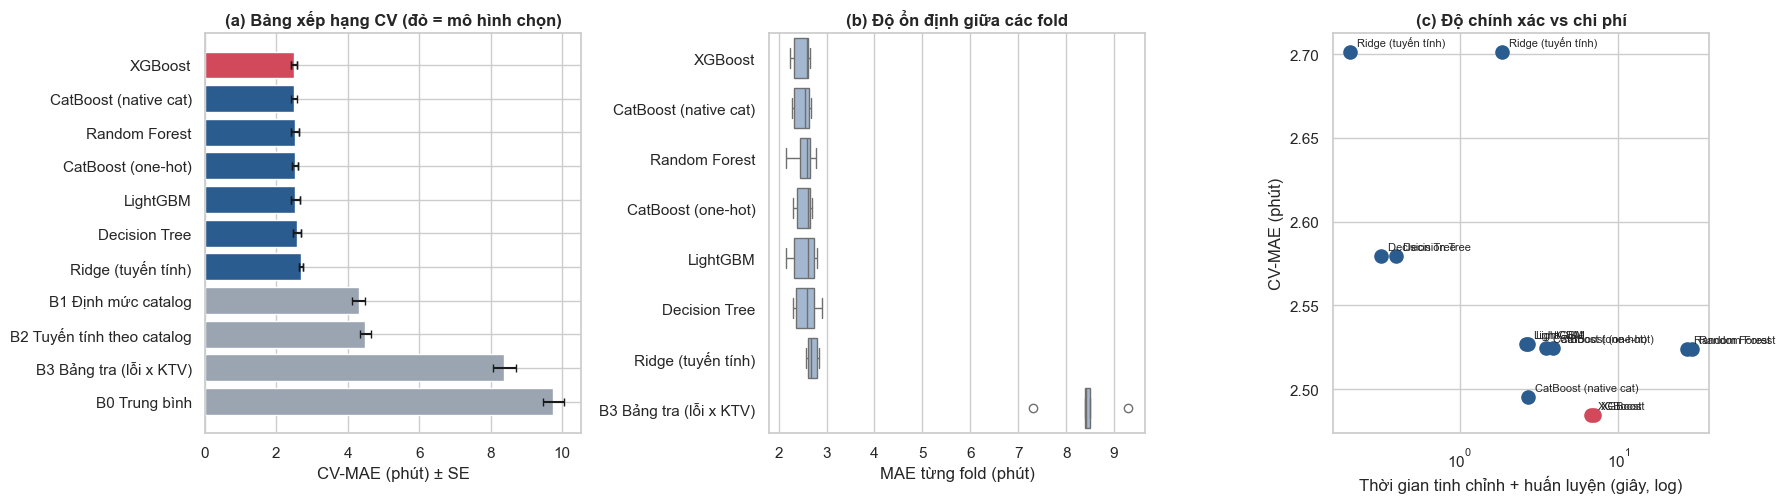

MÔ HÌNH ĐƯỢC CHỌN (theo CV-MAE nhỏ nhất): XGBoost
  CV-MAE = 2.485 ± 0.083 (SE) phút | tham số: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}
  So với baseline B3 (bảng tra lỗi × KTV): MAE thấp hơn 70.4%
  Nhóm hòa thống kê (trong 1 SE của mô hình tốt nhất): ['XGBoost', 'XGBoost', 'CatBoost (native cat)', 'Random Forest', 'Random Forest', 'CatBoost (one-hot)', 'CatBoost (one-hot)', 'LightGBM', 'LightGBM']
  => Các mô hình trong nhóm này KHÔNG tách bạch được bằng CV. Báo cáo như vậy; việc chọn mô hình thắng là chọn theo con số, không phải 'vượt trội rõ rệt'.


In [27]:
cv_df = pd.DataFrame(cv_rows)
models_df = cv_df[cv_df["kind"] == "model"].sort_values("cv_mae").reset_index(drop=True)
best_name = models_df.loc[0, "name"]; best_row = models_df.loc[0]
tie_set = models_df[models_df["cv_mae"] <= best_row["cv_mae"] + best_row["se"]]["name"].tolist()
b3 = cv_df[cv_df["name"].str.startswith("B3")].iloc[0]

board = cv_df.sort_values("cv_mae").reset_index(drop=True)
board.index += 1
display(board[["name", "kind", "cv_mae", "cv_std", "se", "cv_rmse", "cv_r2", "train_time"]].round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
d = board.iloc[::-1]
colors = [BEST_COLOR if n == best_name else (BASE_COLOR if k == "baseline" else NEUTRAL) for n, k in zip(d["name"], d["kind"])]
ax[0].barh(d["name"], d["cv_mae"], xerr=d["se"], color=colors, capsize=3)
ax[0].set(xlabel="CV-MAE (phút) ± SE", title="(a) Bảng xếp hạng CV (đỏ = mô hình chọn)")
order = models_df["name"].tolist() + [b3["name"]]
long = pd.DataFrame([{"mô hình": n, "MAE": v} for n in order for v in cv_df[cv_df["name"] == n]["fold_maes"].iloc[0]])
sns.boxplot(data=long, x="MAE", y="mô hình", order=order, orient="h", ax=ax[1], color="#9bb8d8")
ax[1].set(xlabel="MAE từng fold (phút)", ylabel="", title="(b) Độ ổn định giữa các fold")
for _, r_ in models_df.iterrows():
    ax[2].scatter(r_["train_time"], r_["cv_mae"], s=90, color=BEST_COLOR if r_["name"] == best_name else NEUTRAL)
    ax[2].annotate(r_["name"], (r_["train_time"], r_["cv_mae"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax[2].set(xscale="log", xlabel="Thời gian tinh chỉnh + huấn luyện (giây, log)", ylabel="CV-MAE (phút)", title="(c) Độ chính xác vs chi phí")
plt.tight_layout(); savefig("13_leaderboard_cv"); plt.show()

gain = (1 - best_row["cv_mae"] / b3["cv_mae"]) * 100
print(f"MÔ HÌNH ĐƯỢC CHỌN (theo CV-MAE nhỏ nhất): {best_name}")
print(f"  CV-MAE = {best_row['cv_mae']:.3f} ± {best_row['se']:.3f} (SE) phút | tham số: {best_row['best_params']}")
print(f"  So với baseline B3 (bảng tra lỗi × KTV): MAE {'thấp hơn' if gain >= 0 else 'CAO hơn'} {abs(gain):.1f}%")
print(f"  Nhóm hòa thống kê (trong 1 SE của mô hình tốt nhất): {tie_set}")
if len(tie_set) > 1:
    print("  => Các mô hình trong nhóm này KHÔNG tách bạch được bằng CV. Báo cáo như vậy; việc chọn mô hình thắng là chọn theo con số, không phải 'vượt trội rõ rệt'.")
    simple = [n for n in tie_set if n.startswith(("Ridge", "Decision Tree"))]
    if simple and not best_name.startswith(("Ridge", "Decision Tree")):
        print(f"  => Lưu ý nguyên tắc tiết kiệm (Occam): {simple} nằm trong nhóm hòa và đơn giản, dễ giải thích hơn. Có thể cân nhắc ưu tiên chúng nếu cần giải thích với hội đồng.")
    if best_name.startswith("Ridge"):
        print("  => Mô hình tuyến tính thắng hoặc hòa: dữ liệu gần tuyến tính theo các đặc trưng này; không cần phức tạp hóa bằng cây.")
best_spec, best_est, best_mode = CANDIDATES[best_name], fitted[best_name], CANDIDATES[best_name]["mode"]

## Bước 14. Ablation: sinh thêm dữ liệu (augmentation) có thật sự giúp?

**Nhiệm vụ:** kiểm chứng bằng thực nghiệm thay vì giả định. Augmentation hiện tại nhân bản các dòng train rồi cộng nhiễu Gauss vào nhãn:

$$y' = \max\bigl(15,\ y+\varepsilon\bigr),\qquad \varepsilon\sim\mathcal{N}(0,\,3.5^2)$$

Bản sao giữ **nguyên $\mathbf{x}$**, chỉ nhiễu hóa $y$, nên **không tạo ra thông tin mới** về quan hệ $\mathbf{x}\to y$; nó có thể chỉ làm mô hình "tin" hơn vào các điểm đã có. Cách kiểm tra đúng: cùng mô hình đã chọn, cùng tập test, lặp nhiều lần chia khác nhau, so *chỉ seed* với *seed + augment* và dùng kiểm định ghép cặp Wilcoxon. Augmentation chỉ được thêm vào **tập train** của từng lần chia, test luôn là phiếu thật chưa bị nhân bản.

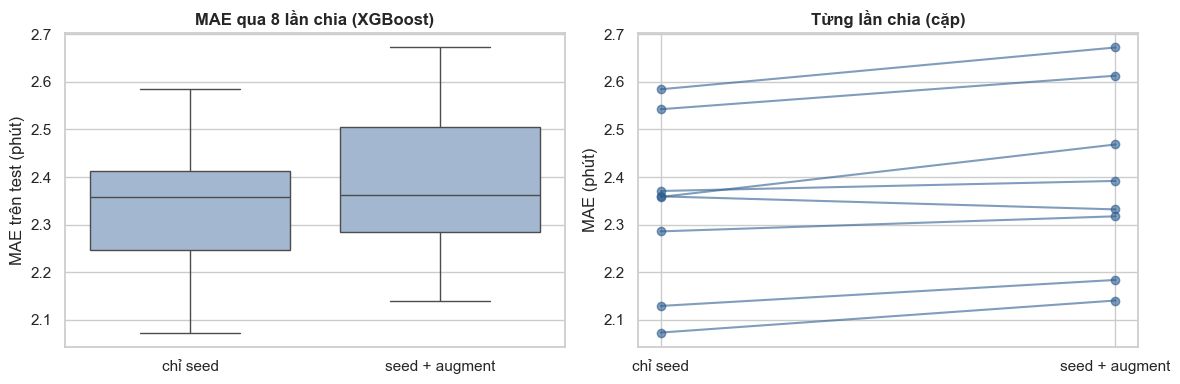

,lần chia,chỉ seed,seed + augment
mean,3.50000,2.337750,2.389875
std,2.44949,0.177551,0.188403


Chênh lệch MAE trung bình (seed − augment) = -0.052 phút | Wilcoxon p = 0.0234
=> Augmentation làm MAE TỆ HƠN có ý nghĩa thống kê. Không dùng: huấn luyện chỉ trên phiếu thật.


In [28]:
n_rep = min(ABLATION_REPEATS, 8)

def eval_split(seed, augment):
    tr_i, te_i = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=seed).split(df_model, groups=df_model[GROUP_COL]))
    tr_df, te_df = df_model.iloc[tr_i].reset_index(drop=True), df_model.iloc[te_i].reset_index(drop=True)
    if augment:
        tr_df = augment_repair_dataset(tr_df, AUGMENT_TARGET_ROWS, seed)
    bld = RepairFeatureBuilder(NUM_COLS, CAT_COLS, ISSUE_COL, cat_mode=best_mode).fit(tr_df)
    m = clone(best_est).fit(bld.transform(tr_df), tr_df[TARGET_COL].to_numpy(float))
    return float(np.mean(np.abs(m.predict(bld.transform(te_df)) - te_df[TARGET_COL].to_numpy(float))))

abl = pd.DataFrame([{"lần chia": s, "chỉ seed": eval_split(s, False), "seed + augment": eval_split(s, True)} for s in range(n_rep)])
diff = abl["chỉ seed"] - abl["seed + augment"]            # dương = augment tốt hơn
try:
    p_abl = float(stats.wilcoxon(abl["chỉ seed"], abl["seed + augment"]).pvalue)
except ValueError:
    p_abl = 1.0
aug_helps = bool(diff.mean() > abl["chỉ seed"].std(ddof=1) and p_abl < 0.05)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=abl[["chỉ seed", "seed + augment"]], ax=ax[0], color="#9bb8d8")
ax[0].set(ylabel="MAE trên test (phút)", title=f"MAE qua {n_rep} lần chia ({best_name})")
for _, r_ in abl.iterrows():
    ax[1].plot([0, 1], [r_["chỉ seed"], r_["seed + augment"]], "o-", color=NEUTRAL, alpha=0.6)
ax[1].set(xticks=[0, 1], xticklabels=["chỉ seed", "seed + augment"], ylabel="MAE (phút)", title="Từng lần chia (cặp)")
plt.tight_layout(); savefig("14_augmentation_ablation"); plt.show()
display(abl.round(3).describe().loc[["mean", "std"]])
print(f"Chênh lệch MAE trung bình (seed − augment) = {diff.mean():+.3f} phút | Wilcoxon p = {p_abl:.3g}")
if aug_helps:
    print("=> Augmentation CÓ lợi rõ rệt. Cân nhắc đặt USE_AUGMENTATION=True và chạy lại toàn bộ notebook.")
elif diff.mean() < 0 and p_abl < 0.05:
    print("=> Augmentation làm MAE TỆ HƠN có ý nghĩa thống kê. Không dùng: huấn luyện chỉ trên phiếu thật.")
else:
    print("=> Augmentation KHÔNG cho lợi ích rõ rệt. Giữ nguyên: huấn luyện chỉ trên phiếu thật, giải thích được và không rủi ro rò rỉ.")

## Bước 15. Đánh giá cuối cùng trên tập test (chạm một lần)

**Nhiệm vụ:** lấy con số hiệu năng **không thiên lệch**. Mô hình đã được chọn ở Bước 13, ta *không được* quay lại đổi mô hình dựa trên điểm test; nếu không, tập test sẽ trở thành tập validation thứ hai và con số mất giá trị.

$$\text{MAE}_{\text{test}}=\frac{1}{N_{\text{test}}}\sum_{j\in D_{\text{test}}}\bigl|y_j-\hat{y}_j\bigr|$$

Mỗi chỉ số kèm khoảng tin cậy bootstrap 95% của MAE (Bước 8). Hai mô hình có khoảng chồng lên nhau thì không kết luận được hơn kém.

,name,kind,MAE,RMSE,R2,P90_abs_err,within_5min_pct,bias,MAE_lo,MAE_hi
1,XGBoost,model,2.111,2.939,0.961,3.938,95.808,0.237,1.837,2.452
2,CatBoost (native cat),model,2.180,3.002,0.959,4.064,93.413,0.201,1.899,2.516
3,CatBoost (one-hot),model,2.183,2.978,0.960,3.937,94.012,0.242,1.905,2.516
4,LightGBM,model,2.312,3.140,0.955,4.463,91.018,0.346,2.015,2.668
5,Random Forest,model,2.327,3.269,0.951,4.294,92.814,0.209,2.006,2.705
6,Decision Tree,model,2.410,3.491,0.945,4.367,91.018,0.140,2.066,2.839
7,Ridge (tuyến tính),model,2.570,3.405,0.947,5.091,89.222,0.334,2.255,2.942
8,B2 Tuyến tính theo catalog,baseline,4.192,6.126,0.829,7.591,67.665,-0.031,3.563,4.902
9,B1 Định mức catalog,baseline,4.437,6.802,0.789,7.400,71.257,0.389,3.742,5.222
10,B3 Bảng tra (lỗi x KTV),baseline,8.112,13.885,0.123,17.380,61.677,-1.599,6.485,9.906


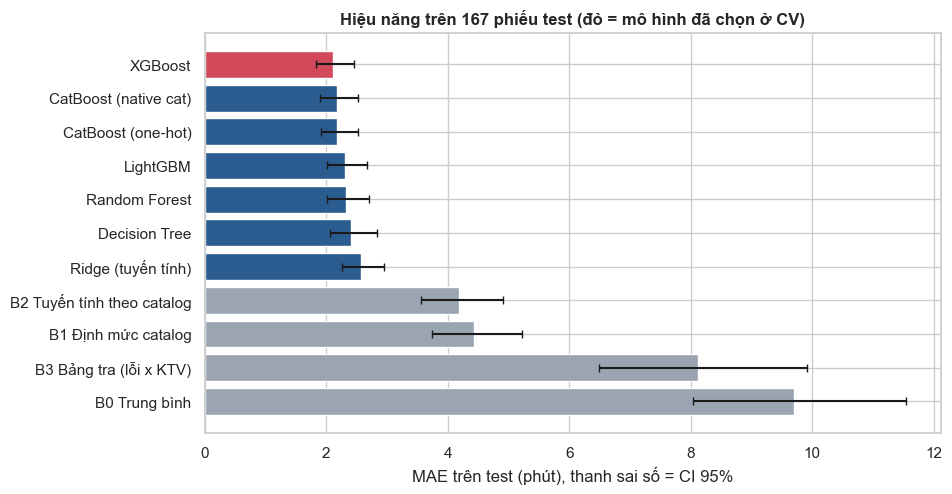

Mô hình chọn theo CV: XGBoost | hạng trên test: 1/11
Lưu ý: nếu hạng test khác hạng CV, ta vẫn giữ lựa chọn theo CV (không chọn lại theo test).


In [29]:
test_pred = {}
for name, spec in CANDIDATES.items():
    test_pred[name] = fitted[name].predict(X_te_mode[spec["mode"]])
for n, p in baseline_predictions(train, test, TARGET_COL, ISSUE_COL).items():
    test_pred[n] = p

rows = []
for n, p in test_pred.items():
    lo, hi = bootstrap_mae_ci(np.abs(p - y_te))
    rows.append({"name": n, "kind": "baseline" if n in base_names else "model", **regression_report(y_te, p), "MAE_lo": lo, "MAE_hi": hi})
test_res = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
test_res.index += 1
display(test_res.round(3))

d = test_res.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = [BEST_COLOR if n == best_name else (BASE_COLOR if k == "baseline" else NEUTRAL) for n, k in zip(d["name"], d["kind"])]
ax.barh(d["name"], d["MAE"], xerr=[d["MAE"] - d["MAE_lo"], d["MAE_hi"] - d["MAE"]], color=colors, capsize=3)
ax.set(xlabel="MAE trên test (phút), thanh sai số = CI 95%", title=f"Hiệu năng trên {len(test)} phiếu test (đỏ = mô hình đã chọn ở CV)")
savefig("15_test_results"); plt.show()

rank_test = int(test_res.index[test_res["name"] == best_name][0])
print(f"Mô hình chọn theo CV: {best_name} | hạng trên test: {rank_test}/{len(test_res)}")
print("Lưu ý: nếu hạng test khác hạng CV, ta vẫn giữ lựa chọn theo CV (không chọn lại theo test).")

### 15.1. Mô hình đã chọn có hơn các đối thủ thật không? (kiểm định ghép cặp)

Hai MAE khác nhau chưa đủ để kết luận; cần biết chênh lệch có vượt qua nhiễu lấy mẫu hay không. Trên **cùng các phiếu test**, đặt $d_j = |e_j^{A}| - |e_j^{B}|$ và dùng **kiểm định Wilcoxon signed-rank** (không giả định phân phối chuẩn):

$$W=\min(W^{+},W^{-}),\qquad W^{\pm}=\sum_{j:\ \pm d_j>0}\text{rank}(|d_j|)$$

Vì so sánh một mô hình với nhiều đối thủ, ngưỡng ý nghĩa được hiệu chỉnh **Bonferroni**: $\alpha' = 0.05/m$ ($m$ là số phép so sánh) để tránh "tìm thấy" khác biệt do may rủi.

In [30]:
e_best = np.abs(test_pred[best_name] - y_te)
m_cmp = len(test_pred) - 1
alpha_adj = 0.05 / m_cmp
rows = []
for n, p in test_pred.items():
    if n == best_name:
        continue
    e_o = np.abs(p - y_te); dlt = e_o - e_best
    try:
        pv = float(stats.wilcoxon(e_o, e_best).pvalue)
    except ValueError:
        pv = 1.0
    verdict = ("mô hình chọn TỐT HƠN có ý nghĩa" if (pv < alpha_adj and dlt.mean() > 0) else
               "mô hình chọn KÉM HƠN có ý nghĩa" if (pv < alpha_adj and dlt.mean() < 0) else "hòa thống kê")
    rows.append({"so với": n, "MAE đối thủ − MAE chọn (phút)": dlt.mean(), "% phiếu mô hình chọn thắng": np.mean(e_best < e_o) * 100,
                 "p-value (Wilcoxon)": pv, f"kết luận (α'={alpha_adj:.4f})": verdict})
wil = pd.DataFrame(rows).sort_values("p-value (Wilcoxon)").reset_index(drop=True)
display(wil.round(4))
p_vs_b3 = float(wil.loc[wil["so với"].str.startswith("B3"), "p-value (Wilcoxon)"].iloc[0])
n_tied = int((wil.iloc[:, -1] == "hòa thống kê").sum())
print(f"Hòa thống kê với {n_tied}/{len(wil)} đối thủ. So với B3 (bảng tra): p = {p_vs_b3:.3g}.")

,so với,MAE đối thủ − MAE chọn (phút),% phiếu mô hình chọn thắng,p-value (Wilcoxon),kết luận (α'=0.0050)
0,B0 Trung bình,7.5837,81.4371,0.0000,mô hình chọn TỐT HƠN có ý nghĩa
1,B1 Định mức catalog,2.3262,70.6587,0.0000,mô hình chọn TỐT HƠN có ý nghĩa
2,B3 Bảng tra (lỗi x KTV),6.0007,68.8623,0.0000,mô hình chọn TỐT HƠN có ý nghĩa
3,B2 Tuyến tính theo catalog,2.0814,71.8563,0.0000,mô hình chọn TỐT HƠN có ý nghĩa
4,Ridge (tuyến tính),0.4588,63.4731,0.0000,mô hình chọn TỐT HƠN có ý nghĩa
5,Decision Tree,0.2992,59.8802,0.0051,hòa thống kê
6,Random Forest,0.2160,53.8922,0.0325,hòa thống kê
7,LightGBM,0.2007,56.8862,0.0410,hòa thống kê
8,CatBoost (one-hot),0.0721,53.2934,0.0736,hòa thống kê
9,CatBoost (native cat),0.0686,53.2934,0.1652,hòa thống kê


Hòa thống kê với 5/10 đối thủ. So với B3 (bảng tra): p = 8.61e-11.


### 15.2. Chẩn đoán sai số của mô hình đã chọn

Một con số MAE che giấu *sai ở đâu*. Sáu biểu đồ:

1. **Dự đoán vs thực tế:** càng sát đường $y=x$ càng tốt.
2. **Phần dư vs dự đoán:** nếu có hình phễu hoặc cong thì mô hình bỏ sót cấu trúc (sai số không đồng đều).
3. **Phân phối phần dư:** nên đối xứng quanh 0; lệch nghĩa là có bias hệ thống.
4. **Q-Q plot:** so phần dư với phân phối chuẩn; đuôi cong nghĩa là có vài ca lệch rất lớn.
5–6. **MAE theo số dịch vụ và theo KTV:** phát hiện nhóm mô hình yếu, để quyết định có cần thêm dữ liệu cho nhóm đó không.

Tỉ lệ $\text{MAE}/\text{RMSE}\approx0.80$ nếu sai số xấp xỉ Gauss; thấp hơn nhiều nghĩa là vài ca lệch rất lớn kéo RMSE lên.

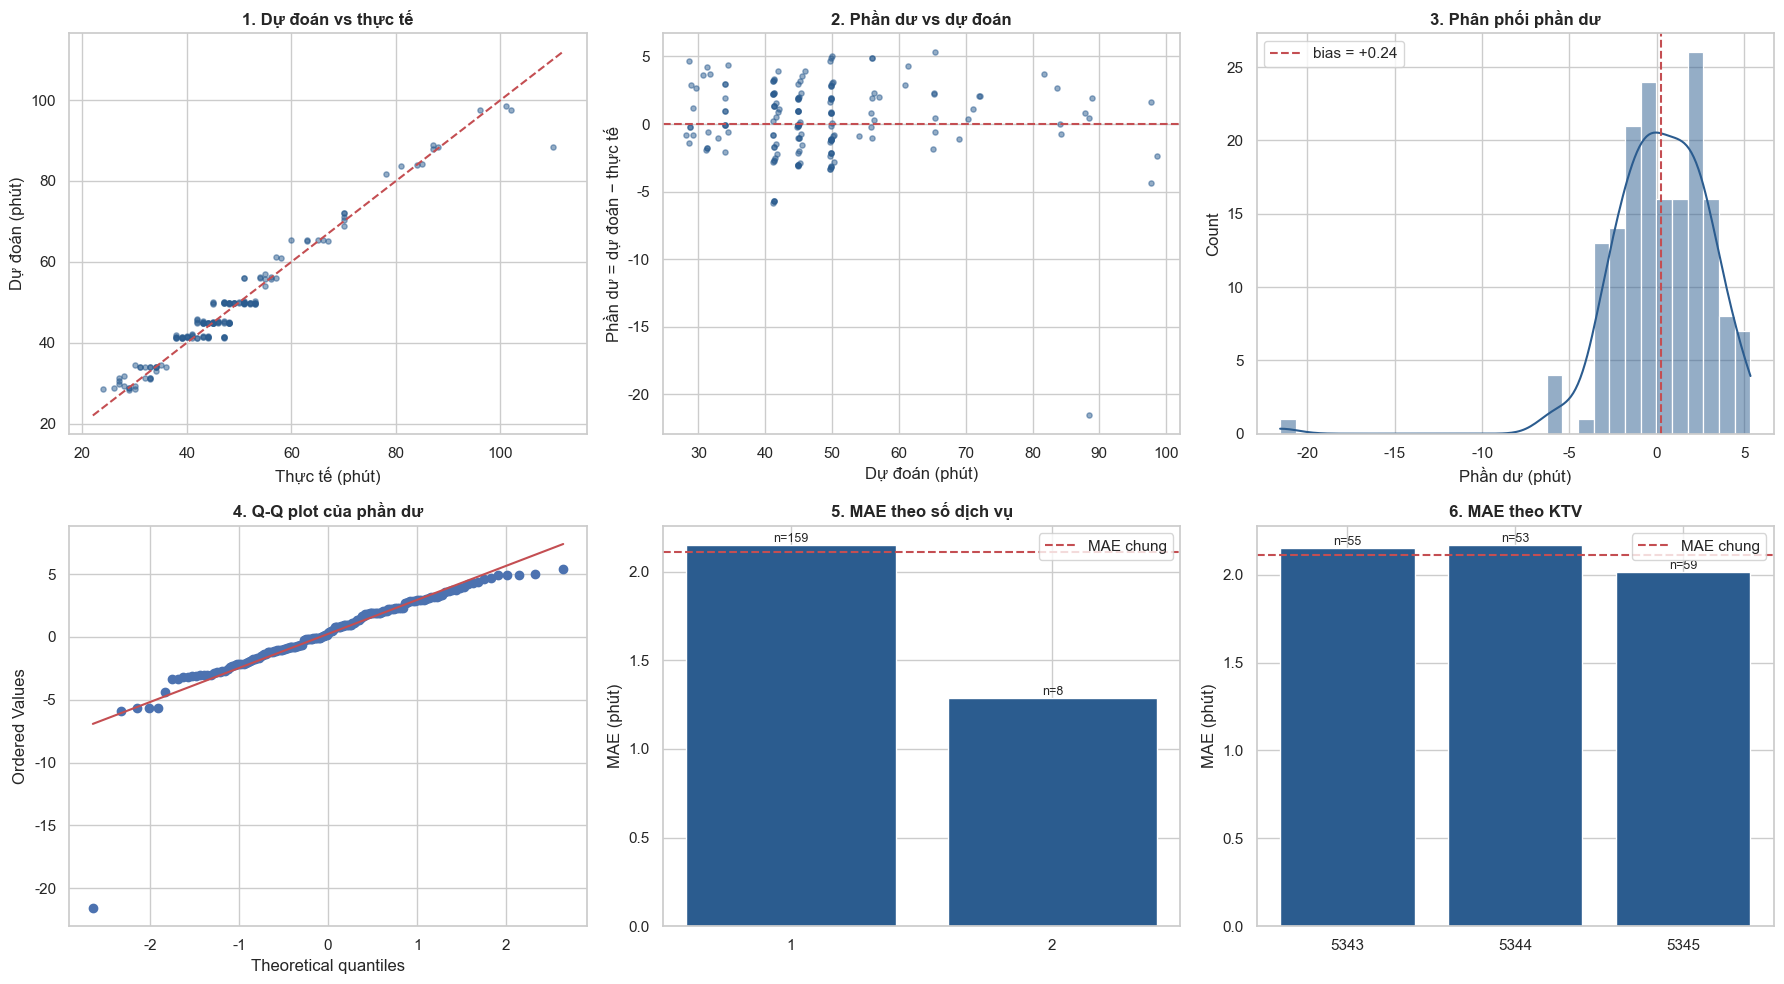

MAE/RMSE = 0.72 (≈0.80 nếu sai số Gauss)
10 phiếu sai nhiều nhất:


,ticket_id,service_issue_ids_list,device_model_id,technician_id,total_services_count,thực tế,dự đoán,sai số tuyệt đối
0,11162,5,1415,5344,1,110.0,88.400002,21.6
1,11177,6,1427,5343,1,47.0,41.099998,5.9
2,11158,4,792,5343,1,47.0,41.299999,5.7
3,11141,3,405,5343,1,47.0,41.299999,5.7
4,11127,2,319,5343,1,47.0,41.299999,5.7
5,11188,5,1442,5345,1,60.0,65.400002,5.4
6,11150,1,789,5345,1,45.0,50.000000,5.0
7,11189,7,1442,5345,1,45.0,49.900002,4.9
8,10947,1,1442,5343,1,51.0,55.900002,4.9
9,10688,1,792,5343,1,51.0,55.900002,4.9


In [31]:
p_b = test_pred[best_name]; res = p_b - y_te
diag = test[[GROUP_COL, ISSUE_COL, "device_model_id", "technician_id", "total_services_count"]].copy()
diag["thực tế"], diag["dự đoán"], diag["sai số tuyệt đối"] = y_te, p_b.round(1), np.abs(res).round(1)

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
ax[0, 0].scatter(y_te, p_b, s=14, alpha=0.5, color=NEUTRAL)
lim = [min(y_te.min(), p_b.min()) - 2, max(y_te.max(), p_b.max()) + 2]; ax[0, 0].plot(lim, lim, "r--")
ax[0, 0].set(xlabel="Thực tế (phút)", ylabel="Dự đoán (phút)", title="1. Dự đoán vs thực tế")
ax[0, 1].scatter(p_b, res, s=14, alpha=0.5, color=NEUTRAL); ax[0, 1].axhline(0, c="r", ls="--")
ax[0, 1].set(xlabel="Dự đoán (phút)", ylabel="Phần dư = dự đoán − thực tế", title="2. Phần dư vs dự đoán")
sns.histplot(res, bins=30, kde=True, ax=ax[0, 2], color=NEUTRAL); ax[0, 2].axvline(res.mean(), c="r", ls="--", label=f"bias = {res.mean():+.2f}")
ax[0, 2].set(xlabel="Phần dư (phút)", title="3. Phân phối phần dư"); ax[0, 2].legend()
stats.probplot(res, dist="norm", plot=ax[1, 0]); ax[1, 0].set_title("4. Q-Q plot của phần dư")
for axx, col, ttl in ((ax[1, 1], "total_services_count", "5. MAE theo số dịch vụ"), (ax[1, 2], "technician_id", "6. MAE theo KTV")):
    g = diag.groupby(col)["sai số tuyệt đối"].agg(["mean", "count"])
    axx.bar(g.index.astype(str), g["mean"], color=NEUTRAL)
    for i, (m_, c_) in enumerate(zip(g["mean"], g["count"])):
        axx.text(i, m_, f"n={c_}", ha="center", va="bottom", fontsize=9)
    axx.axhline(np.abs(res).mean(), c="r", ls="--", label="MAE chung"); axx.set(title=ttl, ylabel="MAE (phút)"); axx.legend()
plt.tight_layout(); savefig("15_2_error_diagnostics"); plt.show()

mae_, rmse_ = np.abs(res).mean(), np.sqrt((res ** 2).mean())
print(f"MAE/RMSE = {mae_ / rmse_:.2f} (≈0.80 nếu sai số Gauss)")
print("10 phiếu sai nhiều nhất:"); display(diag.nlargest(10, "sai số tuyệt đối").reset_index(drop=True))

## Bước 16. Đường cong học (learning curve)

**Nhiệm vụ:** trả lời "có nên thu thập thêm dữ liệu không?" bằng số liệu. Huấn luyện mô hình đã chọn với tỉ lệ dữ liệu tăng dần $n$ và đo MAE trên train và trên fold kiểm định.

* Hai đường **hội tụ về một mức** (khoảng cách nhỏ, đường kiểm định đã phẳng): mô hình đã khai thác hết thông tin trong đặc trưng; thêm dữ liệu không giúp, muốn tốt hơn phải thêm **đặc trưng**/giảm nhiễu nhãn.
* **Khoảng cách lớn** và đường kiểm định còn đi xuống: mô hình khớp quá mức, thêm dữ liệu thật sẽ giúp.

$$\text{Sai số kiểm định} \approx \underbrace{\text{độ chệch}^2}_{\text{mô hình quá đơn giản}} + \underbrace{\text{phương sai}}_{\text{quá ít dữ liệu}} + \underbrace{\sigma^2}_{\text{nhiễu không thể giảm}}$$

Thành phần $\sigma^2$ là **trần nhiễu**: khi hai đường chạm trần này thì không mô hình nào làm tốt hơn.

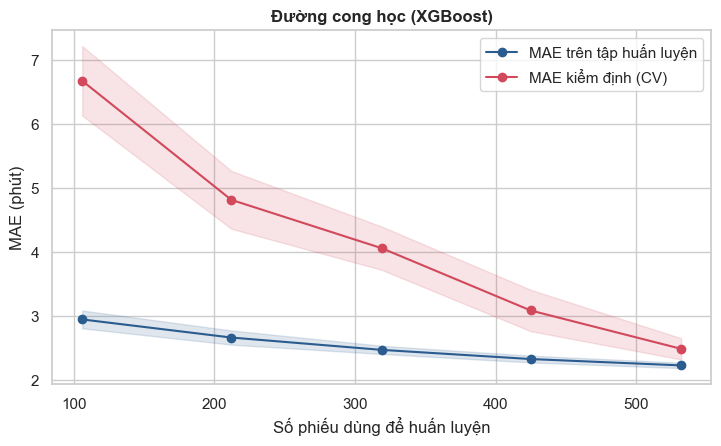

Khoảng cách kiểm định − huấn luyện tại n tối đa = 0.26 phút | mức giảm của MAE kiểm định ở bước cuối = 0.600 phút
=> Đường kiểm định còn đi xuống: thêm dữ liệu thật có khả năng cải thiện mô hình.


In [32]:
sizes, tr_sc, va_sc = learning_curve(clone(best_est), X_tr_mode[best_mode], y_tr, cv=folds, train_sizes=np.linspace(0.2, 1.0, 5),
                                     scoring="neg_mean_absolute_error", n_jobs=1)
tr_m, va_m = -tr_sc.mean(1), -va_sc.mean(1)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(sizes, tr_m, "o-", color=NEUTRAL, label="MAE trên tập huấn luyện")
ax.fill_between(sizes, tr_m - tr_sc.std(1), tr_m + tr_sc.std(1), color=NEUTRAL, alpha=0.15)
ax.plot(sizes, va_m, "o-", color=BEST_COLOR, label="MAE kiểm định (CV)")
ax.fill_between(sizes, va_m - va_sc.std(1), va_m + va_sc.std(1), color=BEST_COLOR, alpha=0.15)
ax.set(xlabel="Số phiếu dùng để huấn luyện", ylabel="MAE (phút)", title=f"Đường cong học ({best_name})"); ax.legend()
savefig("16_learning_curve"); plt.show()
gap = va_m[-1] - tr_m[-1]; slope_end = va_m[-2] - va_m[-1]
print(f"Khoảng cách kiểm định − huấn luyện tại n tối đa = {gap:.2f} phút | mức giảm của MAE kiểm định ở bước cuối = {slope_end:.3f} phút")
print("=> " + ("Đường kiểm định gần phẳng: thêm dữ liệu cùng loại ít giúp; cải thiện tiếp phải đến từ đặc trưng mới hoặc giảm nhiễu nhãn."
               if slope_end < 0.1 else "Đường kiểm định còn đi xuống: thêm dữ liệu thật có khả năng cải thiện mô hình."))

## Bước 17. Giải thích mô hình

**Nhiệm vụ:** mô hình dựa vào cái gì để dự đoán, và có hợp lý nghiệp vụ không? Ba góc nhìn:

**17.1. Permutation importance theo nhóm.** Xáo trộn ngẫu nhiên các hàng của *một nhóm đặc trưng* (cả các cột one-hot của KTV cùng lúc) và đo MAE tăng bao nhiêu. Nhóm quan trọng thì phá nó làm MAE tăng mạnh:

$$\text{PI}_g = \mathbb{E}_{\pi}\bigl[\text{MAE}(\mathbf{X}^{\pi(g)})\bigr]-\text{MAE}(\mathbf{X})$$

Gộp theo nhóm vì one-hot làm importance tích hợp bị chia nhỏ cho từng cột. Tính trên **tập test** nên phản ánh đóng góp khi dự đoán phiếu mới.

**17.2. Phụ thuộc từng phần (PDP) theo định mức catalog.** Đổi catalog của mọi phiếu test sang giá trị $v$ (các đặc trưng dẫn xuất tính lại), lấy trung bình dự đoán:
$$\text{PDP}(v)=\frac{1}{N}\sum_{j}\hat{f}\bigl(\mathbf{x}_j^{(\text{catalog}\leftarrow v)}\bigr)$$

**17.3. "What-if" theo KTV.** Giữ nguyên phiếu, chỉ đổi KTV. Nếu mô hình đã học đúng thì chỉ số tốc độ của mô hình phải **khớp với chỉ số quan sát trực tiếp trong dữ liệu** (Bước 4.3). Đây là kiểm tra then chốt cho mục tiêu *dự đoán theo KTV*.

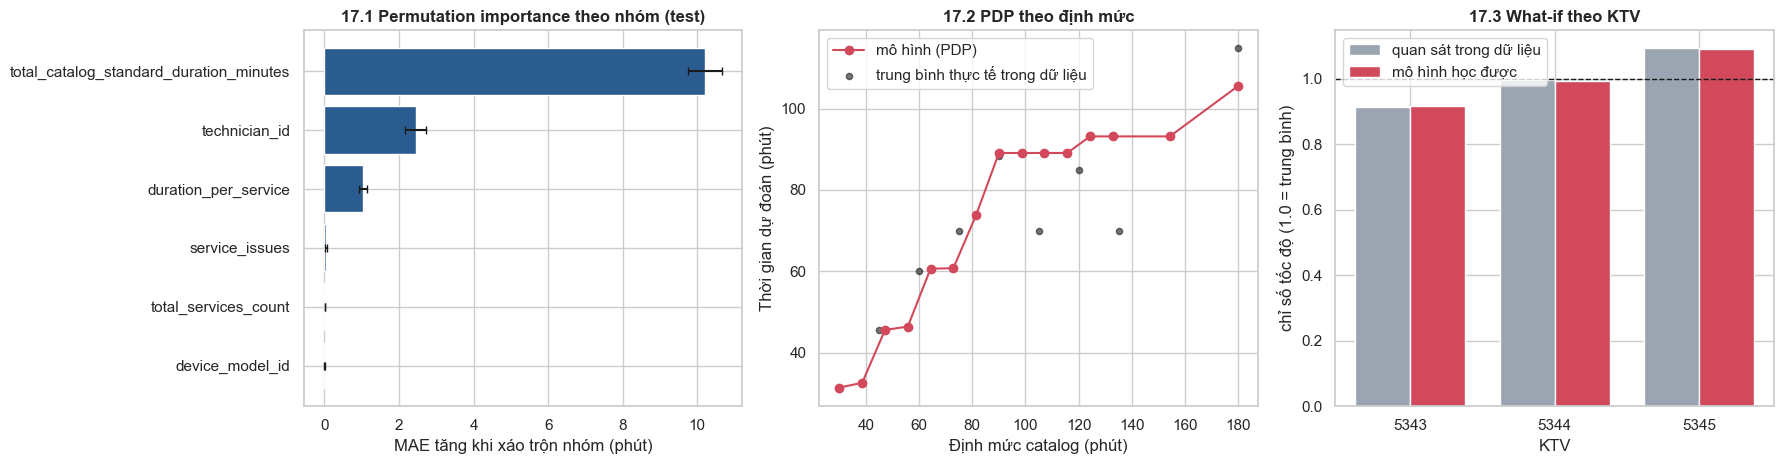

Cùng một phiếu, chênh lệch dự đoán giữa KTV nhanh nhất và chậm nhất = 8.37 phút (trên trung bình 48.4 phút)


,chỉ số quan sát,chỉ số mô hình
5343,0.912,0.917
5344,0.995,0.992
5345,1.093,1.090


In [33]:
bld = builders[best_mode]
Xt = X_te_mode[best_mode]
base_mae = float(np.mean(np.abs(best_est.predict(Xt) - y_te)))

def group_of(col):
    if col.startswith("device_model_id__"): return "device_model_id"
    if col.startswith("technician_id__"): return "technician_id"
    if col.startswith("issue_"): return "service_issues"
    return col
groups = {}
for c in Xt.columns:
    groups.setdefault(group_of(c), []).append(c)

rng = np.random.default_rng(SEED); pi = []
for g, cols in groups.items():
    deltas = []
    for _ in range(20):
        Xp = Xt.copy(); perm = rng.permutation(len(Xt))
        Xp[cols] = Xt[cols].to_numpy()[perm]
        deltas.append(float(np.mean(np.abs(best_est.predict(Xp) - y_te))) - base_mae)
    pi.append((g, np.mean(deltas), np.std(deltas)))
pi = pd.DataFrame(pi, columns=["nhóm", "ΔMAE", "std"]).sort_values("ΔMAE")

# 17.2 PDP theo catalog
grid = np.unique(np.quantile(df_model[CATALOG_COL].unique(), np.linspace(0, 1, 15)))
pdp = [float(np.mean(best_est.predict(bld.transform(test.assign(**{CATALOG_COL: v}))))) for v in grid]
emp = df_model.groupby(CATALOG_COL)[TARGET_COL].mean()

# 17.3 what-if theo KTV
techs = bld.categories_["technician_id"]
mean_pred = pd.Series({t: float(np.mean(best_est.predict(bld.transform(test.assign(technician_id=t))))) for t in techs})
model_idx = mean_pred / mean_pred.mean()
emp_ratio = single.groupby("technician_id")["ratio"].mean().reindex(techs)
emp_idx = emp_ratio / emp_ratio.mean()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].barh(pi["nhóm"], pi["ΔMAE"], xerr=pi["std"], color=NEUTRAL, capsize=3)
ax[0].set(xlabel="MAE tăng khi xáo trộn nhóm (phút)", title="17.1 Permutation importance theo nhóm (test)")
ax[1].plot(grid, pdp, "o-", color=BEST_COLOR, label="mô hình (PDP)")
ax[1].scatter(emp.index, emp.values, s=20, color="k", alpha=0.6, label="trung bình thực tế trong dữ liệu")
ax[1].set(xlabel="Định mức catalog (phút)", ylabel="Thời gian dự đoán (phút)", title="17.2 PDP theo định mức"); ax[1].legend()
w = 0.38; xs = np.arange(len(techs))
ax[2].bar(xs - w / 2, emp_idx.values, w, label="quan sát trong dữ liệu", color=BASE_COLOR)
ax[2].bar(xs + w / 2, model_idx.values, w, label="mô hình học được", color=BEST_COLOR)
ax[2].axhline(1, c="k", lw=1, ls="--"); ax[2].set_xticks(xs); ax[2].set_xticklabels([str(t) for t in techs])
ax[2].set(ylabel="chỉ số tốc độ (1.0 = trung bình)", xlabel="KTV", title="17.3 What-if theo KTV"); ax[2].legend()
plt.tight_layout(); savefig("17_interpretation"); plt.show()

spread = float(mean_pred.max() - mean_pred.min())
print(f"Cùng một phiếu, chênh lệch dự đoán giữa KTV nhanh nhất và chậm nhất = {spread:.2f} phút (trên trung bình {mean_pred.mean():.1f} phút)")
display(pd.DataFrame({"chỉ số quan sát": emp_idx, "chỉ số mô hình": model_idx}).round(3))

## Bước 18. Khoảng dự báo 90% (độ tin cậy của từng dự đoán)

**Nhiệm vụ:** một con số "47 phút" không nói lên độ chắc chắn. Ta cần cả khoảng: "47 phút, khả năng 90% nằm trong [41, 53]".

Dùng **conformal split (phần dư out-of-fold)**: lấy $|r_i| = |y_i-\hat{y}_i^{\text{oof}}|$ từ dự đoán out-of-fold của Bước 12 (mỗi mẫu được dự đoán bởi mô hình chưa thấy nó), rồi

$$\hat{q}=\text{Quantile}_{\lceil(n+1)(1-\alpha)\rceil/n}\bigl(\{|r_i|\}\bigr),\qquad \hat{C}(\mathbf{x})=\bigl[\hat{y}(\mathbf{x})-\hat{q},\ \hat{y}(\mathbf{x})+\hat{q}\bigr]$$

Với dữ liệu hoán đổi được, $\Pr(y\in\hat{C})\ge 1-\alpha$. Ta kiểm chứng bằng **độ phủ thực trên tập test**: nếu khoảng 90% mà phủ ≈ 90% là đạt; phủ quá thấp nghĩa là khoảng quá hẹp, quá cao nghĩa là quá rộng và kém ích lợi.

**Đây là ý nghĩa đúng của "độ tin cậy"** (thay cho việc gán R² của model vào cột `confidence`).

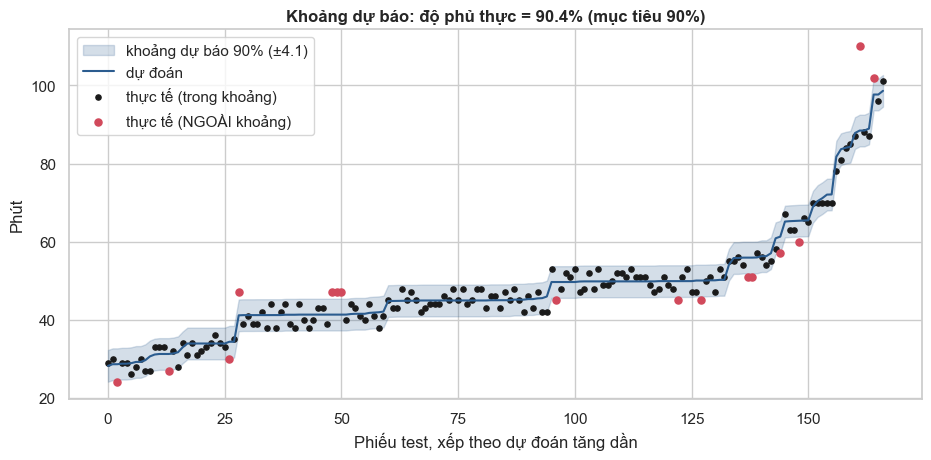

,độ phủ,số phiếu
KTV,,
5343,0.873,55
5344,0.943,53
5345,0.898,59


q̂ = 4.06 phút | độ phủ test = 90.4% | độ rộng khoảng = 8.1 phút


In [34]:
abs_res = np.abs(y_tr - oof_models[best_name]); n_ = len(abs_res)
level = min(1.0, np.ceil((n_ + 1) * INTERVAL_COVERAGE) / n_)
q_hat = float(np.quantile(abs_res, level, method="higher"))
lo_b, hi_b = np.maximum(p_b - q_hat, 0.0), p_b + q_hat
inside = (y_te >= lo_b) & (y_te <= hi_b)
coverage = float(inside.mean())

order = np.argsort(p_b)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(range(len(order)), lo_b[order], hi_b[order], color=NEUTRAL, alpha=0.2, label=f"khoảng dự báo {INTERVAL_COVERAGE:.0%} (±{q_hat:.1f})")
ax.plot(range(len(order)), p_b[order], color=NEUTRAL, lw=1.5, label="dự đoán")
ax.scatter(np.where(inside[order])[0], y_te[order][inside[order]], s=14, color="k", label="thực tế (trong khoảng)")
ax.scatter(np.where(~inside[order])[0], y_te[order][~inside[order]], s=26, color=BEST_COLOR, label="thực tế (NGOÀI khoảng)")
ax.set(xlabel="Phiếu test, xếp theo dự đoán tăng dần", ylabel="Phút", title=f"Khoảng dự báo: độ phủ thực = {coverage:.1%} (mục tiêu {INTERVAL_COVERAGE:.0%})"); ax.legend()
savefig("18_prediction_interval"); plt.show()

by_t = pd.DataFrame({"KTV": test["technician_id"].to_numpy(), "phủ": inside}).groupby("KTV")["phủ"].agg(["mean", "count"]).round(3)
display(by_t.rename(columns={"mean": "độ phủ", "count": "số phiếu"}))
print(f"q̂ = {q_hat:.2f} phút | độ phủ test = {coverage:.1%} | độ rộng khoảng = {2 * q_hat:.1f} phút")

## Bước 19. Đóng gói bundle để đem vào hệ thống

**Nhiệm vụ:** biến kết quả nghiên cứu thành sản phẩm dùng được.

1. **Huấn luyện lại mô hình đã chọn trên toàn bộ dữ liệu sạch** (train + test): sau khi đã *chọn và đánh giá xong*, dùng thêm dữ liệu test để học là hợp lệ và cho mô hình tốt hơn. Số liệu hiệu năng báo cáo vẫn là số của Bước 15 (mô hình chỉ học trên train).
2. **Lưu một file duy nhất** `bundle` gồm: bộ mã hóa đặc trưng + mô hình + metadata (phiên bản, tham số, hiệu năng test, nửa độ rộng khoảng dự báo, cờ dữ liệu mô phỏng, phiên bản thư viện). Một file tránh lỗi "preprocessor một nơi, model một nẻo".
3. **Kiểm tra nạp lại**: nạp bundle từ đĩa và đối chiếu với mô hình trong bộ nhớ, bảo đảm file lưu dùng được ở `05_predict_demo.py`, `06_db_service.py` và `app.py`.

$$\text{Phiếu mới}\ \xrightarrow{\text{builder}}\ \mathbf{x}\ \xrightarrow{\text{model}}\ \hat{y}\ \xrightarrow{\ \pm\hat{q}\ }\ [\hat{y}-\hat{q},\ \hat{y}+\hat{q}]\ \xrightarrow{\text{hàng chờ KTV}}\ \text{ETA}$$

In [35]:
import importlib.metadata as md_

builder_final = RepairFeatureBuilder(NUM_COLS, CAT_COLS, ISSUE_COL, cat_mode=best_mode).fit(df_model)
model_final = clone(best_est).fit(builder_final.transform(df_model), df_model[TARGET_COL].to_numpy(float))

def _ver(pkg):
    try: return md_.version(pkg)
    except Exception: return "n/a"

jsonable = lambda o: o.item() if hasattr(o, "item") else str(o)
test_metrics = regression_report(y_te, p_b)
metadata = {
    "model_name": best_name, "model_version": f"v2-{datetime.now():%Y%m%d}", "trained_at": datetime.now().isoformat(timespec="seconds"),
    "synthetic_data": SYNTHETIC_DATA, "use_augmentation": False,
    "best_params": json.loads(json.dumps(best_row["best_params"], default=jsonable)), "feature_mode": best_mode,
    "n_train_rows_final": int(len(df_model)), "n_test_rows_eval": int(len(test)),
    "test_metrics": test_metrics, "test_mae_ci95": [float(test_res.loc[test_res["name"] == best_name, "MAE_lo"].iloc[0]),
                                                    float(test_res.loc[test_res["name"] == best_name, "MAE_hi"].iloc[0])],
    "baseline_B3_test_metrics": regression_report(y_te, test_pred[[n for n in base_names if n.startswith("B3")][0]]),
    "selection": {"rule": "CV-MAE nhỏ nhất (GroupKFold)", "cv_mae": float(best_row["cv_mae"]), "cv_se": float(best_row["se"]), "statistical_tie_set": tie_set},
    "interval_coverage": INTERVAL_COVERAGE, "interval_halfwidth_minutes": q_hat, "interval_test_coverage": coverage,
    "split_mode": SPLIT_MODE, "cleaning": clean_report, "features": builder_final.feature_names_,
    "technician_ids": builder_final.categories_["technician_id"],
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__,
                 "xgboost": _ver("xgboost"), "lightgbm": _ver("lightgbm"), "catboost": _ver("catboost")},
}
save_bundle(BUNDLE_PATH, builder_final, model_final, metadata)
(REPORTS_DIR / "metrics.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=jsonable), encoding="utf-8")
board.drop(columns="fold_maes").to_csv(REPORTS_DIR / "cv_leaderboard.csv", index_label="rank")
test_res.to_csv(REPORTS_DIR / "test_comparison.csv", index_label="rank")
wil.to_csv(REPORTS_DIR / "paired_tests.csv", index=False)

# Kiểm tra nạp lại từ đĩa
bundle = load_bundle(BUNDLE_PATH)
probe = test.head(5)
loaded = predict_minutes(probe, bundle)
direct = np.round(np.maximum(model_final.predict(builder_final.transform(probe)), MIN_PREDICTED_MINUTES), 1)
assert np.allclose(loaded["predicted_minutes"].to_numpy(), direct), "Bundle nạp lại cho kết quả khác mô hình gốc!"
print(f"Đã lưu bundle: {BUNDLE_PATH}")
print(f"Báo cáo (CSV/JSON/PNG): {REPORTS_DIR}")
print("Kiểm tra nạp lại: OK (bundle trên đĩa cho dự đoán trùng mô hình trong bộ nhớ)")
display(pd.DataFrame({"thực tế": probe[TARGET_COL].to_numpy(), "dự đoán": loaded["predicted_minutes"].to_numpy(),
                      "cận dưới": loaded["lower_minutes"].to_numpy(), "cận trên": loaded["upper_minutes"].to_numpy()}))
print("(Mô hình đóng gói đã học cả các phiếu này, bảng chỉ để kiểm tra nạp lại; không dùng để đánh giá.)")

Đã lưu bundle: D:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\models\v2\repair_duration_bundle.joblib
Báo cáo (CSV/JSON/PNG): D:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\reports
Kiểm tra nạp lại: OK (bundle trên đĩa cho dự đoán trùng mô hình trong bộ nhớ)


,thực tế,dự đoán,cận dưới,cận trên
0,70.0,71.500000,67.400002,75.500000
1,85.0,83.599998,79.500000,87.599998
2,70.0,69.800003,65.699997,73.800003
3,45.0,49.799999,45.799999,53.900002
4,60.0,65.000000,60.900002,69.000000


(Mô hình đóng gói đã học cả các phiếu này, bảng chỉ để kiểm tra nạp lại; không dùng để đánh giá.)


## Bước 20. Tổng kết

Ô code dưới đây **tự tổng hợp kết luận từ kết quả vừa chạy** (không điền tay con số), kèm các cảnh báo trung thực cần nói với hội đồng.

In [36]:
bt = test_res[test_res["name"] == best_name].iloc[0]
b3t = test_res[test_res["name"].str.startswith("B3")].iloc[0]
b1t = test_res[test_res["name"].str.startswith("B1")].iloc[0]
imp_b3 = (1 - bt["MAE"] / b3t["MAE"]) * 100

print("=" * 78); print("TỔNG KẾT"); print("=" * 78)
print(f"1. Dữ liệu : {len(df)} phiếu sạch ({'MÔ PHỎNG' if SYNTHETIC_DATA else 'vận hành thật'}), {df['technician_id'].nunique()} KTV, "
      f"{df['device_model_id'].nunique()} thiết bị. Tách train/test theo phiếu ({len(train)}/{len(test)}).")
print(f"2. Tín hiệu KTV: ANOVA p = {p_anova:.3g}, η² = {eta2:.3f} ({effect}). What-if: KTV nhanh nhất cách chậm nhất {spread:.1f} phút.")
print(f"3. Cuộc thi : {len(CANDIDATES)} mô hình + 4 baseline, cùng {CV_FOLDS} fold theo phiếu, đều được tinh chỉnh tham số.")
print(f"   Chọn theo CV-MAE nhỏ nhất: {best_name} ({best_row['cv_mae']:.3f} ± {best_row['se']:.3f} phút). Nhóm hòa thống kê: {tie_set}.")
print(f"4. Test ({len(test)} phiếu): MAE = {bt['MAE']:.2f} phút (CI95% {bt['MAE_lo']:.2f}–{bt['MAE_hi']:.2f}), RMSE = {bt['RMSE']:.2f}, "
      f"R² = {bt['R2']:.3f}, {bt['within_5min_pct']:.0f}% ca lệch ≤ 5 phút.")
print(f"5. So baseline: định mức catalog (B1) MAE = {b1t['MAE']:.2f}; bảng tra (B3) MAE = {b3t['MAE']:.2f} -> MAE mô hình {'thấp hơn' if imp_b3 >= 0 else 'CAO hơn'} B3 {abs(imp_b3):.1f}% (Wilcoxon p = {p_vs_b3:.3g}).")
print(f"6. Khoảng dự báo {INTERVAL_COVERAGE:.0%}: ±{q_hat:.1f} phút, độ phủ thực trên test = {coverage:.1%}.")
print(f"7. Augmentation: {'có lợi rõ rệt' if aug_helps else ('làm kém đi, không dùng' if (diff.mean() < 0 and p_abl < 0.05) else 'không lợi rõ rệt, không dùng')}. Bundle: {BUNDLE_PATH.name}")

print("\nCẢNH BÁO TRUNG THỰC (nên nói chủ động với hội đồng):")
if SYNTHETIC_DATA:
    print(" - Dữ liệu là mô phỏng: các con số đo độ khớp với quy luật mô phỏng, chưa phải hiệu năng vận hành thật.")
if not ktv_signal:
    print(" - Dữ liệu KHÔNG có tín hiệu KTV: chưa thể tuyên bố mô hình dự đoán khác nhau theo KTV. Sửa script sinh dữ liệu trước.")
if p_vs_b3 >= 0.05 or imp_b3 < 5:
    print(" - Mô hình chỉ hơn bảng tra B3 rất ít / không có ý nghĩa: giá trị của ML là tổng quát hóa cho tổ hợp chưa gặp, không phải độ chính xác trên tổ hợp đã quen.")
if len(tie_set) > 1:
    print(f" - Nhiều mô hình hòa thống kê ({', '.join(tie_set)}): không nên nói '{best_name} vượt trội', chỉ nói 'được chọn theo CV-MAE nhỏ nhất'.")
print(" - Nhãn lấy từ phiếu đã hoàn tất; lúc dự đoán sớm có thể thiếu hạng mục phát sinh sau, vì vậy cần dự đoán lại khi hạng mục thay đổi.")

TỔNG KẾT
1. Dữ liệu : 832 phiếu sạch (MÔ PHỎNG), 3 KTV, 21 thiết bị. Tách train/test theo phiếu (665/167).
2. Tín hiệu KTV: ANOVA p = 1.55e-92, η² = 0.409 (lớn). What-if: KTV nhanh nhất cách chậm nhất 8.4 phút.
3. Cuộc thi : 7 mô hình + 4 baseline, cùng 5 fold theo phiếu, đều được tinh chỉnh tham số.
   Chọn theo CV-MAE nhỏ nhất: XGBoost (2.485 ± 0.083 phút). Nhóm hòa thống kê: ['XGBoost', 'XGBoost', 'CatBoost (native cat)', 'Random Forest', 'Random Forest', 'CatBoost (one-hot)', 'CatBoost (one-hot)', 'LightGBM', 'LightGBM'].
4. Test (167 phiếu): MAE = 2.11 phút (CI95% 1.84–2.45), RMSE = 2.94, R² = 0.961, 96% ca lệch ≤ 5 phút.
5. So baseline: định mức catalog (B1) MAE = 4.44; bảng tra (B3) MAE = 8.11 -> MAE mô hình thấp hơn B3 74.0% (Wilcoxon p = 8.61e-11).
6. Khoảng dự báo 90%: ±4.1 phút, độ phủ thực trên test = 90.4%.
7. Augmentation: làm kém đi, không dùng. Bundle: repair_duration_bundle.joblib

CẢNH BÁO TRUNG THỰC (nên nói chủ động với hội đồng):
 - Dữ liệu là mô phỏng: các con số 

### Dùng kết quả vào hệ thống

1. Bundle nằm ở `models/v2/repair_duration_bundle.joblib`; `05_predict_demo.py`, `06_db_service.py` và `app.py` nạp trực tiếp file này, không cần sửa code khi đổi mô hình (tên mô hình, phiên bản, khoảng dự báo, cờ dữ liệu mô phỏng đều lấy từ metadata).
2. `scripts/03_train_evaluate.py` là bản dòng lệnh cố định XGBoost để huấn luyện lại nhanh. **Notebook này là nơi so sánh và chọn mô hình**; nếu mô hình thắng không phải XGBoost thì huấn luyện lại bằng notebook này.
3. Sau triển khai: chạy `07_monitor_feedback.py` định kỳ để so dự đoán với thời gian thực tế; khi MAE thực tế vượt ngưỡng thì chạy lại notebook với dữ liệu mới.

### Câu hỏi hội đồng có thể hỏi (chuẩn bị trả lời bằng kết quả ở trên)

* *Vì sao chọn mô hình này?* Bảng xếp hạng CV (Bước 13) và kiểm định ghép cặp (Bước 15.1), kèm nhóm hòa thống kê.
* *Làm sao biết không bị rò rỉ dữ liệu?* Bước 5 (cột cấm, `assert`), Bước 6 (tách theo phiếu, `assert` rời nhau), builder chỉ `fit` trên train.
* *ML hơn cách đơn giản bao nhiêu?* So với B1/B3 ở Bước 15 và 15.1.
* *Con số này tin được đến đâu?* Khoảng tin cậy bootstrap của MAE (Bước 8, 15) và khoảng dự báo 90% (Bước 18).
* *Dữ liệu có đủ không?* Đường cong học (Bước 16).
* *Mô hình học được khác biệt giữa các KTV không?* ANOVA (4.3) và what-if (17.3).
* *Sinh thêm dữ liệu có đáng không?* Ablation (Bước 14).